# Expert Systems Results

Notebook for reproducing results in the paper "Generating Stable and Metastable Critical Points in Uncertain Systems via Flow-based Models"

Relevant data are available [here](https://doi.org/10.15129/ecc01ad5-efce-4127-9232-b887b6a2a907).

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
from numpy import pi, cos, sin, arctan2
from tqdm.notebook import tqdm, trange
import json
from pprint import pprint
from datetime import datetime as dt
import pandas as pd

from functools import partial
from itertools import product
from inspect import signature

from scipy.stats import ttest_ind
from scipy.optimize import minimize, root
from scipy.integrate import solve_ivp, odeint
from sklearn.metrics import confusion_matrix, r2_score

import seaborn as sns
from matplotlib import ticker, cm
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

import tensorflow as tf
from tfFlow.utils import *

from optdist import OptDist, RastriginDist, SchwefelDist, WhitleyDist, get_min_rast, get_min_rot_rast, get_min_schwefel, get_min_rot_schwefel, get_min_whitley, get_min_rot_whitley, get_opt_fns, f_opt_rot_batch
from potentialdist import PotentialDist, CR5BPDist, get_crit_cr5bp, get_minima_classes_cr5bp

In [3]:
PATH_TO_DATA = 'DataESGenepy/'
PATH_TO_MODELS = 'ModelsESGenepy/'

In [4]:
def sample_with_noise(mindata, N_noise, N_tot, N_check=None, seed_noise=None, seed_samp=None, scale=1e-3):
    N = mindata.shape[0]
    m = mindata.shape[1]
    rng_noise = np.random.default_rng(seed=seed_noise)
    noise_all = rng_noise.normal(loc=[0.]*m,scale=[scale,scale]+[0.]*(m-2),size=(N,N_noise,m))
    psamp_all = (np.expand_dims(mindata,1) + noise_all).reshape(-1,m)
    
    rng_samp = np.random.default_rng(seed=seed_samp)
    psamp_data = rng_samp.choice(psamp_all,size=N_tot,replace=False)

    if N_check is not None:
        mindiff_all = np.linalg.norm(np.expand_dims(psamp_data,0)-np.expand_dims(mindata,1),axis=-1)
        min_true = np.any(mindiff_all[:N_check,:]<0.01,axis=-1)
        del mindiff_all
        print(f'N min {N} min sampled {np.sum(min_true)}')

    return psamp_data

def fvals_to_labels(fvals, bins):
    lab_all = np.digitize(fvals,bins)
    fval_class = pd.get_dummies(lab_all-1).values.astype(np.float32)
    return fval_class

## Function Plots

In [5]:
def plot_gx(g_func, 
            xmax=1.,
            xmin=None,
            ymax=None,
            N_sq=250,
            levels=np.linspace(0,1,6),
            figsize=(6,5), 
            ctitle=None,
            cmap='viridis'):
    if xmin is None:
        xmin=-xmax
    x = y = np.linspace(xmin, xmax, N_sq, endpoint=True, dtype=np.float32)
    if ymax is not None:
        y = np.linspace(-ymax, ymax, N_sq, endpoint=True, dtype=np.float32)
        
    X, Y = np.meshgrid(x, y)
    X_grid = np.stack([X.flatten(), Y.flatten()], axis=-1)
    g_arr = g_func(X_grid)
    print(f'Min {np.min(g_arr):.3f} Max {np.max(g_arr):.3f}')
    
    fig, ax = plt.subplots(figsize=figsize)
    cs = ax.contourf(X, Y, g_arr.reshape(N_sq,N_sq), levels=levels, cmap=cmap)
    ax.set_xlabel('x',fontsize=12)
    ax.set_ylabel('y',fontsize=12)
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.2)
    cbar = fig.colorbar(cs, cax=cax)
    if ctitle is not None:
        cbar.ax.set_title(ctitle,pad=10,fontsize=12)
    
    return fig, ax

def f_opt_rot(x, dist, theta, dx):
    M_neg = np.array([[
        [cos(theta), sin(theta)],
        [-sin(theta), cos(theta)]
    ]],dtype=np.float64)
    x_rot = np.array([np.matmul(M_neg, xt-dx)+dx for xt in x])
    return dist.f_np(x_rot)

Min 0.078 Max 42.000


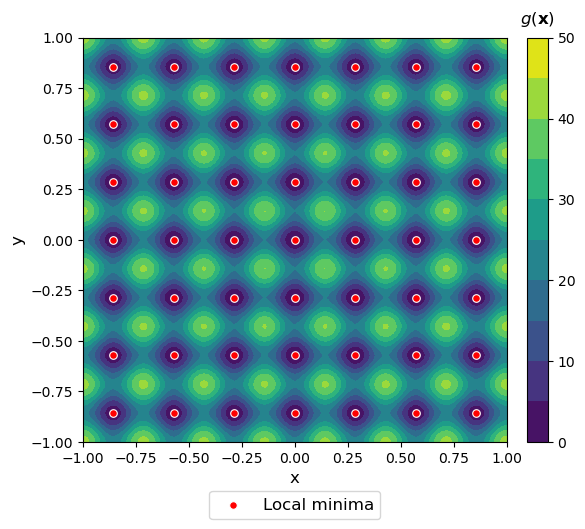

In [6]:
omega = 3.5
theta = 0.*np.pi/180.
dx = np.array([0., 0.])
dist = RastriginDist(omega=omega)
g_func = lambda x: f_opt_rot(x, dist, theta, dx)
min_all = get_min_rot_rast(omega, theta)

fig, ax = plot_gx(g_func, 
                  levels=np.linspace(0,50,11), 
                  figsize=(6,7),
                  ctitle=r'$g(\mathbf{x})$')
ax.scatter(min_all[:,0],min_all[:,1],
           marker='o',facecolor='r',edgecolor='white',linewidths=0.8,s=30,
           label='Local minima')

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.25,
                 box.width, box.height * 0.75])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.1),
                fontsize=12,
                ncols=1
               )

Min -3315.701 Max 4439.292


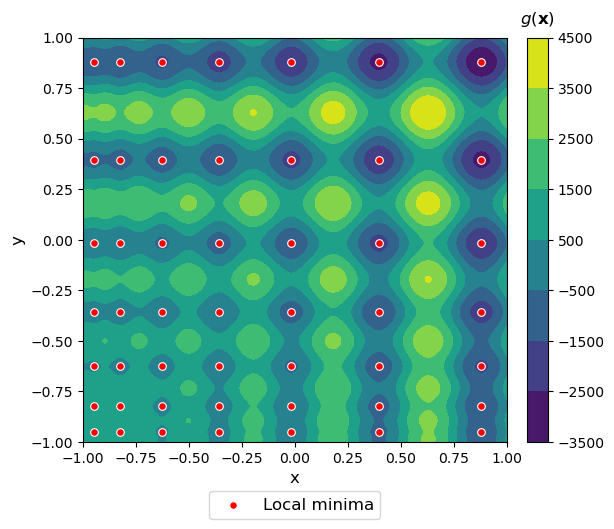

In [7]:
omega = 1100
theta = 0.*np.pi/180.
dx = np.array([1., -1.])
min_x = 10./omega
shift = 1. + min_x
dist = SchwefelDist(omega=omega, shift=shift)
g_func = lambda x: f_opt_rot(x, dist, theta, dx)
min_all = get_min_rot_schwefel(omega, theta, min_x=min_x, dx=dx)

fig, ax = plot_gx(g_func, N_sq=400, 
                  levels=np.linspace(-3.5e3,4.5e3,9), 
                  figsize=(6,7),
                  ctitle=r'$g(\mathbf{x})$')
ax.scatter(min_all[:,0],min_all[:,1],
           marker='o',facecolor='r',edgecolor='white',linewidths=0.8,s=30,
           label='Local minima')

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.25,
                 box.width, box.height * 0.75])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.1),
                fontsize=12,
                ncols=1
               )

Min 0.000 Max 7.307


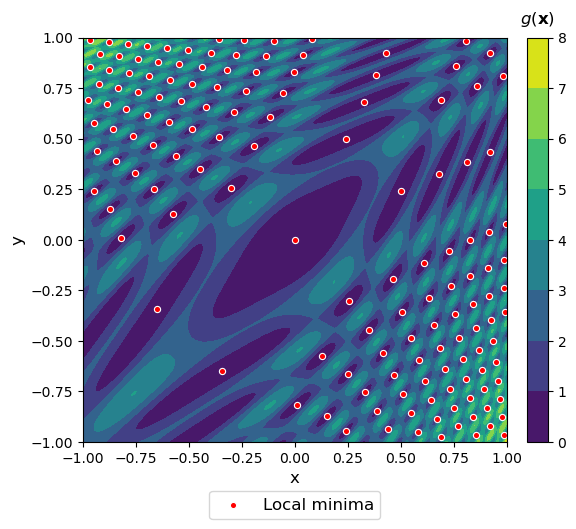

In [8]:
omega = 0.3
dist = WhitleyDist(omega=omega)
g_func = dist.f_np
min_all = get_min_whitley(omega)

fig, ax = plot_gx(g_func, N_sq=400, 
                  levels=np.linspace(0,8,9), 
                  figsize=(6,7),
                  ctitle=r'$g(\mathbf{x})$')
ax.scatter(min_all[:,0],min_all[:,1],
           marker='o',facecolor='r',edgecolor='white',linewidths=0.8,s=20,
           label='Local minima')

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.25,
                 box.width, box.height * 0.75])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.1),
                fontsize=12,
                ncols=1
               )

Min 0.513 Max 67.101


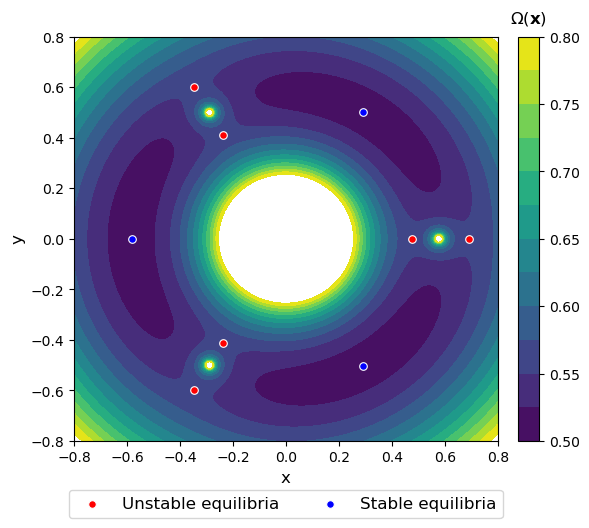

In [9]:
mu = 0.02
xmax = 0.8
dist = CR5BPDist(mu_min=0.,mu_max=mu)
g_func = lambda x: dist.f_np(x, np.ones(x.shape[0]))
min_all = get_crit_cr5bp(1., mu_min=0., mu_max=mu)
stab_min = np.array([False,False,True]*3)

fig, ax = plot_gx(g_func, 
                  xmax=xmax, 
                  N_sq=400, 
                  levels=np.linspace(0.5,0.8,13), 
                  figsize=(6,7),
                  ctitle=r'$\Omega(\mathbf{x})$')
ax.scatter(min_all[~stab_min,0],min_all[~stab_min,1],
           marker='o',facecolor='r',edgecolor='white',s=30,linewidths=0.8,
           label='Unstable equilibria')
ax.scatter(min_all[stab_min,0],min_all[stab_min,1],
           marker='o',facecolor='b',edgecolor='white',s=30,linewidths=0.8,
           label='Stable equilibria')

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.25,
                 box.width, box.height * 0.75])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.1),
                fontsize=12,
                ncols=2
               )

Min 1.462 Max 166.220


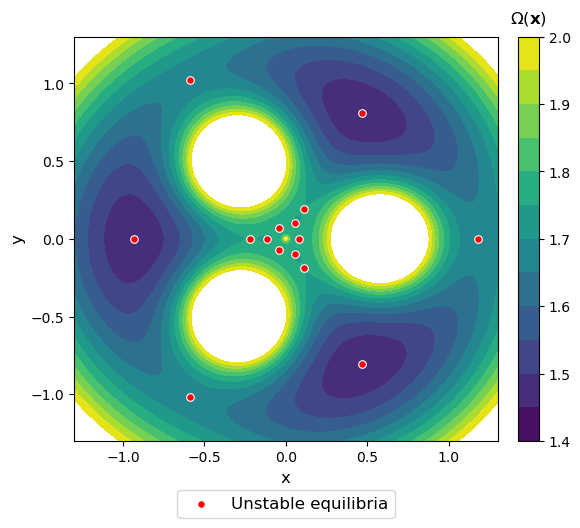

In [10]:
mu = 0.992
xmax = 1.3
dist = CR5BPDist(mu_min=0.,mu_max=mu)
g_func = lambda x: dist.f_np(x, np.ones(x.shape[0]))
min_all = get_crit_cr5bp(1., mu_min=0., mu_max=mu)

fig, ax = plot_gx(g_func, 
                  xmax=xmax, 
                  N_sq=400, 
                  levels=np.linspace(1.4,2.,13), 
                  figsize=(6,7),
                  ctitle=r'$\Omega(\mathbf{x})$')
ax.scatter(min_all[:,0],min_all[:,1],
           marker='o',facecolor='r',edgecolor='white',s=30,linewidths=0.8,
           label='Unstable equilibria')

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.25,
                 box.width, box.height * 0.75])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.1),
                fontsize=12,
                ncols=1
               )

In [11]:
def calc_z(s,mu):
    scale = 0.7
    w1=15
    c = np.array([
        [-scale,0.],
        [scale,0.]
    ])
    curvature=0.01;
    w3 = np.array([2.,mu])
    
    z = curvature*(s[0]**2+s[1]**2)
    nc = c.shape[0]
    for k in range(nc):
        z += -w3[k]*np.exp( -w1 * ((s[0]-c[k,0])**2 + (s[1]-c[k,1])**2) )
    return z

def f_root_1d(s,mu=0.1):
    scale = 0.7
    w1=15
    c = np.array([
        [-scale,0.],
        [scale,0.]
    ])
    curvature=0.01;
    w3 = np.array([2.,mu])
    
    dzdx=-curvature*2*s
    nc = c.shape[0]
    for k in range(nc):
        dzdx -= w3[k]*w1*np.exp(-w1*(s-c[k,0])**2)*2*(s-c[k,0])
    return dzdx

Min -1.995 Max 0.023


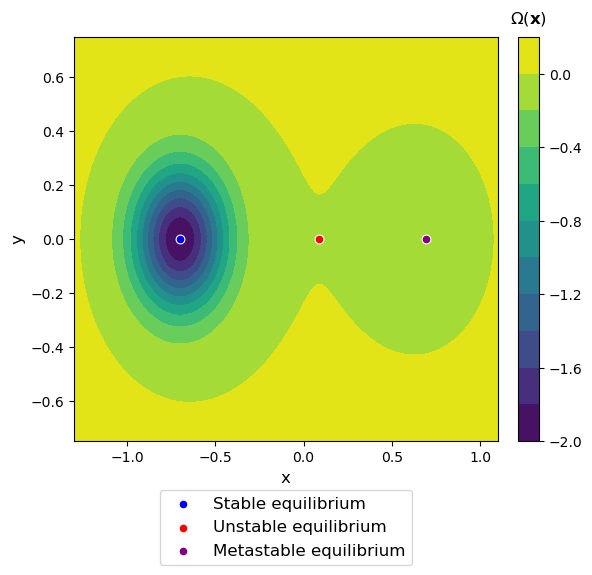

In [12]:
mu = 0.1
xmin = -1.3
xmax = 1.1
ymax = 0.75
g_func = lambda x: np.array([calc_z(s,mu) for s in x])
f_root = partial(f_root_1d,mu=mu)

x0_stab = -0.7
res = root(f_root, x0_stab)
min_stab = [res.x[0],0]

x0_us = 0.
res = root(f_root, x0_us)
min_us = [res.x[0],0]

x0_meta = 0.6
res = root(f_root, x0_meta)
min_meta = [res.x[0],0]

fig, ax = plot_gx(g_func, 
                  xmax=xmax, 
                  xmin=xmin,
                  ymax=ymax,
                  N_sq=400, 
                  levels=np.linspace(-2,0.2,12), 
                  figsize=(6,7),
                  ctitle=r'$\Omega(\mathbf{x})$')
min_kwargs = dict(marker='o',edgecolor='white',s=40,linewidths=0.8,)
ax.scatter(min_stab[0],min_stab[1],facecolor='b',label='Stable equilibrium',**min_kwargs)
ax.scatter(min_us[0],min_us[1],facecolor='r',label='Unstable equilibrium',**min_kwargs)
ax.scatter(min_meta[0],min_meta[1],facecolor='purple',label='Metastable equilibrium',**min_kwargs)

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.25,
                 box.width, box.height * 0.75])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.1),
                fontsize=12,
                ncols=1
               )

Text(0, 0.5, '$\\Omega(x,0)$')

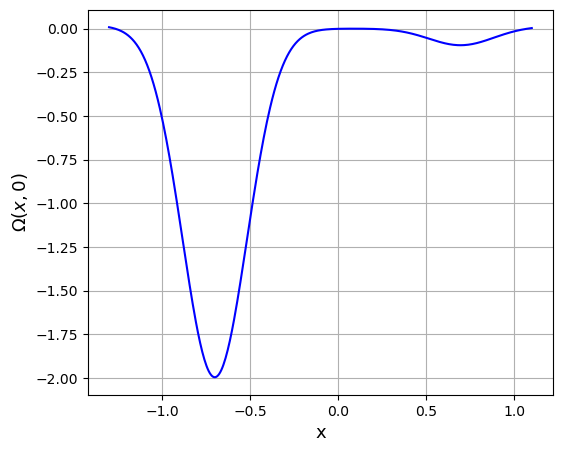

In [13]:
s_range = np.linspace(-1.3,1.1,400)
z_plot = [calc_z([s,0.],mu) for s in s_range]
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(s_range,z_plot,color='b')
ax.grid()
ax.set_xlabel('x',fontsize=13)
ax.set_ylabel(r'$\Omega(x,0)$',fontsize=13)

## Iterative Retraining

In [5]:
def load_retrain_data(problem, parameter, fvals):
    dirname = os.path.join(PATH_TO_DATA,'Retraining/')
    fname = f'_{problem}_{parameter}_{fvals}'
    nfev_all = []
    nmin_all = []
    for run_no in range(32):
        fname_run = fname + '_run' + str(run_no)
        fname_data = 'mindata' + fname_run + '.json'
        with open(os.path.join(dirname,fname_data),'r') as f:
            data_run = json.load(f)
        fname_init = 'mindata' + fname_run + '_init.json'
        with open(os.path.join(dirname,fname_init),'r') as f:
            data_init = json.load(f)
        nfev_run = np.concatenate([d['nfev'] for d in data_run['opt']])
        newmin_run = np.concatenate([d['newmin'] for d in data_run['opt']])
        ind_max = np.where(newmin_run)[0][-1]
        nfev_all.append(np.sum(nfev_run[:ind_max+1])+np.sum(data_init['nfev']))
        nmin_all.append(np.sum(newmin_run)+np.sum(data_init['newmin']))
    return nfev_all, nmin_all

def load_random_data(problem, parameter):
    dirname = os.path.join(PATH_TO_DATA,'Retraining/')
    fname = f'random_{problem}_{parameter}.json'
    with open(dirname+fname,'r') as f:
        data_rand = json.load(f)
    nfev_all = [np.sum(d['nfev']) for d in data_rand]
    nmin_all = [np.sum(d['newmin']) for d in data_rand]
    return nfev_all, nmin_all

### Rastrigin

In [6]:
problem = 'Rastrigin'
omega_str = 'omega3p5'

nfev_fvals_3p5, nmin_fvals_3p5 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_3p5, nmin_xonly_3p5 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_3p5, nmin_rand_3p5 = load_random_data(problem,omega_str)

In [7]:
ttest_ind(nfev_fvals_3p5,nfev_rand_3p5,random_state=12345678)

TtestResult(statistic=2.1890547626092425, pvalue=0.03236694602439446, df=62.0)

In [8]:
problem = 'Rastrigin'
omega_str = 'omega5p5'

nfev_fvals_5p5, nmin_fvals_5p5 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_5p5, nmin_xonly_5p5 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_5p5, nmin_rand_5p5 = load_random_data(problem,omega_str)

In [9]:
ttest_ind(nfev_fvals_5p5,nfev_rand_5p5,random_state=12345678)

TtestResult(statistic=4.024007623092743, pvalue=0.00015809646432235938, df=62.0)

In [10]:
problem = 'Rastrigin'
omega_str = 'omega7p5'

nfev_fvals_7p5, nmin_fvals_7p5 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_7p5, nmin_xonly_7p5 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_7p5, nmin_rand_7p5 = load_random_data(problem,omega_str)

In [11]:
ttest_ind(nfev_fvals_7p5,nfev_rand_7p5,random_state=12345678)

TtestResult(statistic=4.153602101552855, pvalue=0.00010188392957701919, df=62.0)

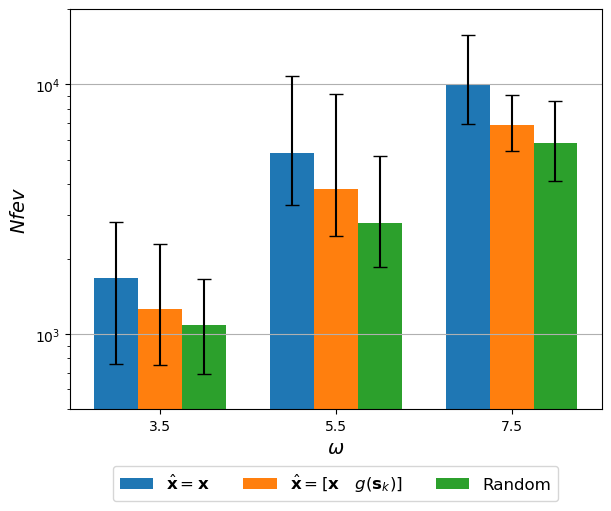

In [12]:
data_rand = [nfev_rand_3p5, nfev_rand_5p5, nfev_rand_7p5]
data_xonly = [nfev_xonly_3p5, nfev_xonly_5p5, nfev_xonly_7p5]
data_fvals = [nfev_fvals_3p5, nfev_fvals_5p5, nfev_fvals_7p5]

omega_all = [3.5, 5.5, 7.5]
nmin_all = [49, 121, 225]

x = np.arange(3)  # the label locations
width = 0.25  # the width of the bars
multiplier = 0

labels_all=[
    r'$\hat{\mathbf{x}}=\mathbf{x}$', 
    r'$\hat{\mathbf{x}}=[ \mathbf{x} \quad g(\mathbf{s}_k) ]$', 
    'Random']
fig, ax = plt.subplots(figsize=(6,5),layout='constrained')
for d_plot, label, c in zip(
    [data_xonly, data_fvals, data_rand],
    labels_all,
    ['r','g','b']
):
    mean_plot = np.array([np.mean(d) for d in d_plot])
    std_plot = np.array([np.std(d) for d in d_plot])
    min_plot = np.array([np.min(d) for d in d_plot])
    max_plot = np.array([np.max(d) for d in d_plot])
    yerr = np.vstack([
        mean_plot-min_plot,
        max_plot-mean_plot
    ])
    offset = width * multiplier
    rects = ax.bar(x + offset, mean_plot, width, 
                   # color=c,
                   label=label,
                   yerr=yerr,
                   capsize=5
                  )
    multiplier += 1
ax.grid(axis='y')
ax.set_xticks(x + width, omega_all)
ax.set_yscale('log')
ax.set_ylim(5e2,2e4)
ax.set_xlabel(r'$\omega$',fontsize=14)
ax.set_ylabel(r'$Nfev$',fontsize=14)

leg = ax.legend(loc='upper center',
                ncols=3,
                bbox_to_anchor=(0.5,-0.12),
                fontsize=12)

### Schwefel

In [13]:
problem = 'Schwefel'
omega_str = 'omega1100'

nfev_fvals_1100, nmin_fvals_1100 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_1100, nmin_xonly_1100 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_1100, nmin_rand_1100 = load_random_data(problem,omega_str)

In [14]:
ttest_ind(nfev_fvals_1100,nfev_rand_1100,random_state=12345678)

TtestResult(statistic=-0.15511399131527223, pvalue=0.8772353374427342, df=62.0)

In [15]:
problem = 'Schwefel'
omega_str = 'omega2700'

nfev_fvals_2700, nmin_fvals_2700 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_2700, nmin_xonly_2700 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_2700, nmin_rand_2700 = load_random_data(problem,omega_str)

In [16]:
ttest_ind(nfev_fvals_2700,nfev_rand_2700,random_state=12345678)

TtestResult(statistic=-5.149414219578397, pvalue=2.8673560328230298e-06, df=62.0)

In [17]:
problem = 'Schwefel'
omega_str = 'omega4300'

nfev_fvals_4300, nmin_fvals_4300 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_4300, nmin_xonly_4300 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_4300, nmin_rand_4300 = load_random_data(problem,omega_str)

In [18]:
ttest_ind(nfev_fvals_4300,nfev_rand_4300,random_state=12345678)

TtestResult(statistic=-5.645973800792375, pvalue=4.3751426063572925e-07, df=62.0)

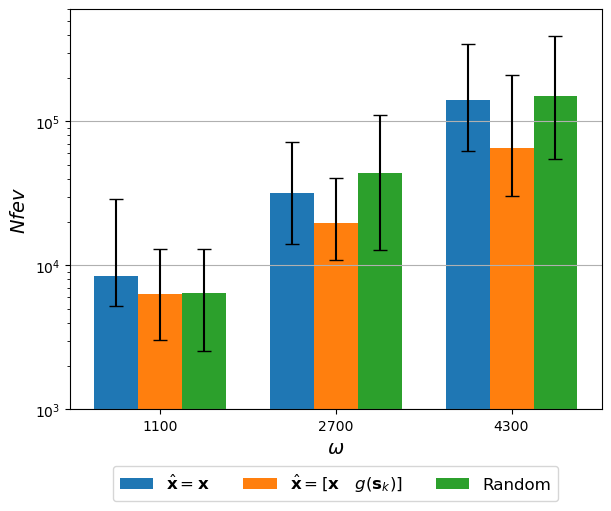

In [19]:
data_rand = [nfev_rand_1100, nfev_rand_2700, nfev_rand_4300]
data_xonly = [nfev_xonly_1100, nfev_xonly_2700, nfev_xonly_4300]
data_fvals = [nfev_fvals_1100, nfev_fvals_2700, nfev_fvals_4300]

omega_all = [1100, 2700, 4300]
nmin_all = [49, 121, 196]

x = np.arange(3)  # the label locations
width = 0.25  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(figsize=(6,5),layout='constrained')
labels_all=[
    r'$\hat{\mathbf{x}}=\mathbf{x}$', 
    r'$\hat{\mathbf{x}}=[ \mathbf{x} \quad g(\mathbf{s}_k) ]$', 
    'Random']
for d_plot, label, c in zip(
    [data_xonly, data_fvals, data_rand],
    labels_all,
    ['r','g','b']
):
    mean_plot = np.array([np.mean(d) for d in d_plot])
    std_plot = np.array([np.std(d) for d in d_plot])
    min_plot = np.array([np.min(d) for d in d_plot])
    max_plot = np.array([np.max(d) for d in d_plot])
    yerr = np.vstack([
        mean_plot-min_plot,
        max_plot-mean_plot
    ])
    offset = width * multiplier
    rects = ax.bar(x + offset, mean_plot, width, 
                   # color=c,
                   label=label,
                   yerr=yerr,
                   capsize=5
                  )
    multiplier += 1
ax.grid(axis='y')
ax.set_xticks(x + width, omega_all)
ax.set_yscale('log')
ax.set_ylim(1e3,6e5)
ax.set_xlabel(r'$\omega$',fontsize=14)
ax.set_ylabel(r'$Nfev$',fontsize=14)

leg = ax.legend(loc='upper center',
                ncols=3,
                bbox_to_anchor=(0.5,-0.12),
                fontsize=12)

### Whitley

In [20]:
problem = 'Whitley'
omega_str = 'omega0p2'

nfev_fvals_0p2, nmin_fvals_0p2 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_0p2, nmin_xonly_0p2 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_0p2, nmin_rand_0p2 = load_random_data(problem,omega_str)

In [21]:
ttest_ind(nfev_fvals_0p2,nfev_rand_0p2,random_state=12345678)

TtestResult(statistic=-1.2082039484289182, pvalue=0.23155707112193008, df=62.0)

In [22]:
problem = 'Whitley'
omega_str = 'omega0p3'

nfev_fvals_0p3, nmin_fvals_0p3 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_0p3, nmin_xonly_0p3 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_0p3, nmin_rand_0p3 = load_random_data(problem,omega_str)

In [23]:
ttest_ind(nfev_fvals_0p3,nfev_rand_0p3,random_state=12345678)

TtestResult(statistic=-6.075569787641578, pvalue=8.291420600669098e-08, df=62.0)

In [24]:
problem = 'Whitley'
omega_str = 'omega0p4'

nfev_fvals_0p4, nmin_fvals_0p4 = load_retrain_data(problem,omega_str,'fvals')
nfev_xonly_0p4, nmin_xonly_0p4 = load_retrain_data(problem,omega_str,'xonly')
nfev_rand_0p4, nmin_rand_0p4 = load_random_data(problem,omega_str)

In [25]:
ttest_ind(nfev_fvals_0p4,nfev_rand_0p4,random_state=12345678)

TtestResult(statistic=-12.469902392764748, pvalue=5.2852603604429274e-15, df=38.0)

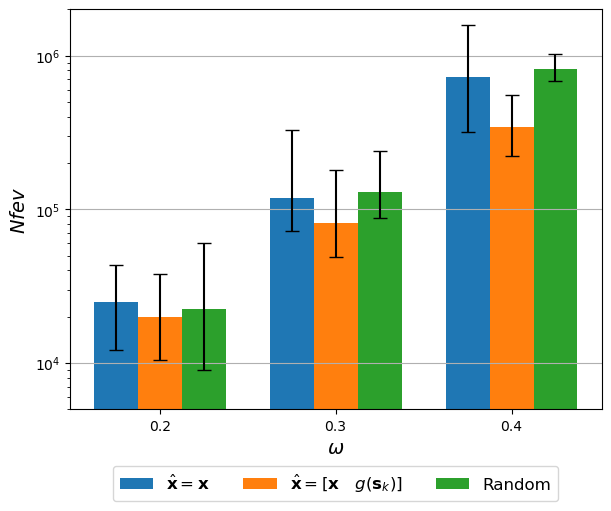

In [26]:
data_rand = [nfev_rand_0p2, nfev_rand_0p3, nfev_rand_0p4]
data_xonly = [nfev_xonly_0p2, nfev_xonly_0p3, nfev_xonly_0p4]
data_fvals = [nfev_fvals_0p2, nfev_fvals_0p3, nfev_fvals_0p4]

omega_all = [0.2, 0.3, 0.4]
nmin_all = [29, 143, 462]

x = np.arange(3)  # the label locations
width = 0.25  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(figsize=(6,5),layout='constrained')
labels_all=[
    r'$\hat{\mathbf{x}}=\mathbf{x}$', 
    r'$\hat{\mathbf{x}}=[ \mathbf{x} \quad g(\mathbf{s}_k) ]$', 
    'Random']
for d_plot, label, c in zip(
    [data_xonly, data_fvals, data_rand],
    labels_all,
    ['r','g','b']
):
    mean_plot = np.array([np.mean(d) for d in d_plot])
    std_plot = np.array([np.std(d) for d in d_plot])
    min_plot = np.array([np.min(d) for d in d_plot])
    max_plot = np.array([np.max(d) for d in d_plot])
    yerr = np.vstack([
        mean_plot-min_plot,
        max_plot-mean_plot
    ])
    offset = width * multiplier
    rects = ax.bar(x + offset, mean_plot, width, 
                   # color=c,
                   label=label,
                   yerr=yerr,
                   capsize=5
                  )
    multiplier += 1
ax.grid(axis='y')
ax.set_xticks(x + width, omega_all)
ax.set_yscale('log')
ax.set_ylim(5e3,2e6)
ax.set_xlabel(r'$\omega$',fontsize=14)
ax.set_ylabel(r'$Nfev$',fontsize=14)

leg = ax.legend(loc='upper center',
                ncols=3,
                bbox_to_anchor=(0.5,-0.12),
                fontsize=12)

### CR5BP

In [27]:
problem = 'CR5BP'
mu_str = 'mu0p02'

nfev_fvals_0p02, nmin_fvals_0p02 = load_retrain_data(problem,mu_str,'fvals')
nfev_xonly_0p02, nmin_xonly_0p02 = load_retrain_data(problem,mu_str,'xonly')
nfev_rand_0p02, nmin_rand_0p02 = load_random_data(problem,mu_str)

In [28]:
ttest_ind(nfev_fvals_0p02,nfev_rand_0p02,random_state=12345678)

TtestResult(statistic=0.15610763647803075, pvalue=0.8764553666714734, df=62.0)

In [29]:
problem = 'CR5BP'
mu_str = 'mu0p992'

nfev_fvals_0p992, nmin_fvals_0p992 = load_retrain_data(problem,mu_str,'fvals')
nfev_xonly_0p992, nmin_xonly_0p992 = load_retrain_data(problem,mu_str,'xonly')
nfev_rand_0p992, nmin_rand_0p992 = load_random_data(problem,mu_str)

In [30]:
ttest_ind(nfev_fvals_0p992,nfev_rand_0p992,random_state=12345678)

TtestResult(statistic=-5.336065512967008, pvalue=1.4232338543010152e-06, df=62.0)

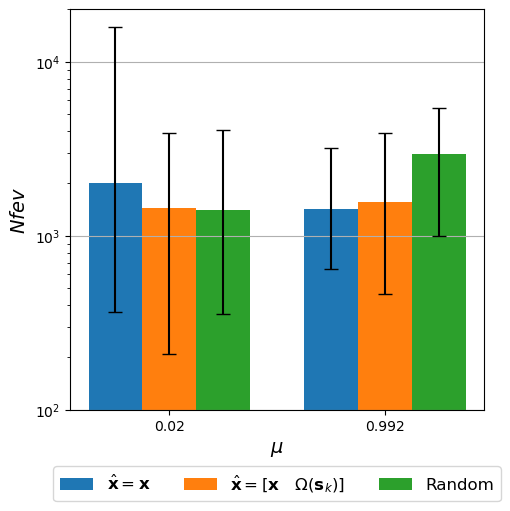

In [31]:
data_rand = [nfev_rand_0p02, nfev_rand_0p992]
data_xonly = [nfev_xonly_0p02, nfev_xonly_0p992]
data_fvals = [nfev_fvals_0p02, nfev_fvals_0p992]

mu_all = [0.02, 0.992]
nmin_all = [9, 15]

x = np.arange(2)  # the label locations
width = 0.25  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(figsize=(5,5),layout='constrained')
labels_all=[
    r'$\hat{\mathbf{x}}=\mathbf{x}$', 
    r'$\hat{\mathbf{x}}=[ \mathbf{x} \quad \Omega(\mathbf{s}_k) ]$', 
    'Random']
for d_plot, label, c in zip(
    [data_xonly, data_fvals, data_rand],
    labels_all,
    ['r','g','b']
):
    mean_plot = np.array([np.mean(d) for d in d_plot])
    std_plot = np.array([np.std(d) for d in d_plot])
    min_plot = np.array([np.min(d) for d in d_plot])
    max_plot = np.array([np.max(d) for d in d_plot])
    yerr = np.vstack([
        mean_plot-min_plot,
        max_plot-mean_plot
    ])
    offset = width * multiplier
    rects = ax.bar(x + offset, mean_plot, width, 
                   # color=c,
                   label=label,
                   yerr=yerr,
                   capsize=5
                  )
    multiplier += 1

ax.grid(axis='y')
ax.set_xticks(x + width, mu_all)
ax.set_yscale('log')
ax.set_ylim(1e2,2e4)
ax.set_xlabel(r'$\mu$',fontsize=14)
ax.set_ylabel(r'$Nfev$',fontsize=14)

leg = ax.legend(loc='upper center',
                ncols=3,
                bbox_to_anchor=(0.5,-0.12),
                fontsize=12)

## Uncertain Parameters Training Data

In [5]:
def get_x_c_norm(norm_all, distname):
    min_all = []
    c_all = []
    if distname=='CR5BP':
        murange = [0.005,0.995]
        for n in norm_all:
            min_new = get_crit_cr5bp(n, mu_min=murange[0], mu_max=murange[1])
            min_all.extend([m for m in min_new])
            c_all.extend([[n]]*min_new.shape[0])
    else: 
        thetarange = [0., 10.]
        if distname=='Rastrigin':
            omrange = [3.5,4.5]
            f_get_min = get_min_rot_rast
        elif distname=='Schwefel':
            omrange = [1100,1800]
            dx = np.array([1.,-1.])
            f_get_min = lambda om, t: get_min_rot_schwefel(om,t,dx=dx,min_x=10./om)
        elif distname=='Whitley':
            omrange = [0.2, 0.3]
            f_get_min = get_min_rot_whitley
        for n1,n2 in product(norm_all,norm_all):
            omega = omrange[0] + 0.5*(n1+1)*(omrange[1]-omrange[0])
            theta = thetarange[0] + 0.5*(n2+1)*(thetarange[1]-thetarange[0])
            min_new = f_get_min(omega, theta*np.pi/180.)
            min_all.extend([m for m in min_new])
            c_all.extend([[n1,n2]]*min_new.shape[0])
    x_tf = tf.constant(min_all,dtype=tf.float32)
    c_tf = tf.constant(c_all,dtype=tf.float32)
    return x_tf, c_tf

### Rastrigin Training Data

In [6]:
omrange_rast = [3.5,4.5]
thetarange_rast = [0.,10.]
norm_all = [-1. , -0.8, -0.4,  0. ,  0.4,  0.8,  1. ]
omega_all_rast = [omrange_rast[0] + 0.5*(n+1)*(omrange_rast[1]-omrange_rast[0]) for n in norm_all]
theta_all_rast = [thetarange_rast[0] + 0.5*(n+1)*thetarange_rast[1] for n in norm_all]
print(omega_all_rast)
print(theta_all_rast)

[3.5, 3.6, 3.8, 4.0, 4.2, 4.4, 4.5]
[0.0, 0.9999999999999998, 3.0, 5.0, 7.0, 9.0, 10.0]


In [7]:
min_params_all = []
for n_omega, n_theta in product(norm_all, norm_all):
    omega = omrange_rast[0] + 0.5*(n_omega+1)*(omrange_rast[1]-omrange_rast[0])
    theta = thetarange_rast[0] + 0.5*(n_theta+1)*(thetarange_rast[1]-thetarange_rast[0])
    min_new = get_min_rot_rast(omega, theta*np.pi/180.)
    min_params_all.extend(
        [list(m)+[n_omega, n_theta] for m in min_new]
    )
min_params_all = np.array(min_params_all)
print(min_params_all.shape)

(3177, 4)


In [ ]:
fig, axs = plt.subplots(1,2,figsize=(12,5))
axs[0].scatter(min_params_all[:,0],min_params_all[:,1],c=min_params_all[:,2], s=8)
axs[1].scatter(min_params_all[:,0],min_params_all[:,1],c=min_params_all[:,3], s=8)

In [9]:
N_train = 2**13
N_val = 1024
print((N_train+N_val)/min_params_all.shape[0])

2.9008498583569406


In [10]:
psamp_data = sample_with_noise(min_params_all, 3, 2**13+1024, 
                               N_check = 2**13, 
                               seed_noise = 12345678, 
                               seed_samp = 123456789)

N min 3177 min sampled 3177


Save as tensor

In [ ]:
psave_tf = tf.constant(psamp_data,dtype=tf.float32)
fname_save = 'traindata_Rastrigin_omega_3p5_4p5_theta_0_10_n7'
save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Parameters'),fname=fname_save)

Save as csv

In [ ]:
df_save = pd.DataFrame(data=psamp_data,columns=['x','y','omega_norm','theta_norm'])
fname_csv = 'traindata_Rastrigin_omega_3p5_4p5_theta_0_10_n7.csv'
df_save.to_csv(os.path.join(PATH_TO_DATA,'Parameters/'+fname_csv),index=False)

### Schwefel Training Data

In [6]:
omrange_sfl = [1100.,1800.]
thetarange_sfl = [0.,10.]
norm_all = [-1. , -0.8, -0.4,  0. ,  0.4,  0.8,  1. ]
omega_all_sfl = [omrange_sfl[0] + 0.5*(n+1)*(omrange_sfl[1]-omrange_sfl[0]) for n in norm_all]
theta_all_sfl = [thetarange_sfl[0] + 0.5*(n+1)*thetarange_sfl[1] for n in norm_all]
print(omega_all_sfl)
print(theta_all_sfl)

[1100.0, 1170.0, 1310.0, 1450.0, 1590.0, 1730.0, 1800.0]
[0.0, 0.9999999999999998, 3.0, 5.0, 7.0, 9.0, 10.0]


In [7]:
min_params_all = []
for n_omega, n_theta in product(norm_all, norm_all):
    omega = omrange_sfl[0] + 0.5*(n_omega+1)*(omrange_sfl[1]-omrange_sfl[0])
    theta = thetarange_sfl[0] + 0.5*(n_theta+1)*(thetarange_sfl[1]-thetarange_sfl[0])
    min_x = 10./omega
    dx = np.array([1.,-1.])
    min_new = get_min_rot_schwefel(omega, theta*np.pi/180., min_x=min_x, dx=dx)
    min_params_all.extend(
        [list(m)+[n_omega, n_theta] for m in min_new]
    )
min_params_all = np.array(min_params_all)
min_params_all.shape

(2494, 4)

In [ ]:
fig, axs = plt.subplots(1,2,figsize=(12,5))
axs[0].scatter(min_params_all[:,0],min_params_all[:,1],c=min_params_all[:,2], s=8)
axs[1].scatter(min_params_all[:,0],min_params_all[:,1],c=min_params_all[:,3], s=8)

In [9]:
N_train = 2**13
N_val = 1024
print((N_train+N_val)/min_params_all.shape[0])

3.6952686447473937


In [10]:
psamp_data = sample_with_noise(min_params_all, 4, 2**13+1024, 
                               N_check = 2**13, 
                               seed_noise = 12345678, 
                               seed_samp = 1234567)

N min 2494 min sampled 2494


Save as tensor

In [ ]:
psave_tf = tf.constant(psamp_data,dtype=tf.float32)
fname_save = 'traindata_Schwefel_omega_1100_1800_theta_0_10_n7'
save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Parameters'),fname=fname_save)

Save as csv

In [ ]:
df_save = pd.DataFrame(data=psamp_data,columns=['x','y','omega_norm','theta_norm'])
fname_csv = 'traindata_Schwefel_omega_1100_1800_theta_0_10_n7.csv'
df_save.to_csv(os.path.join(PATH_TO_DATA,'Parameters/'+fname_csv),index=False)

### Whitley Training Data

In [6]:
omrange_wly = [0.2,0.3]
thetarange_wly = [0.,10.]
norm_all = [-1. , -0.8, -0.4,  0. ,  0.4,  0.8,  1. ]
omega_all_wly = [omrange_wly[0] + 0.5*(n+1)*(omrange_wly[1]-omrange_wly[0]) for n in norm_all]
theta_all_wly = [thetarange_wly[0] + 0.5*(n+1)*thetarange_wly[1] for n in norm_all]
print(omega_all_wly)
print(theta_all_wly)

[0.2, 0.21000000000000002, 0.23, 0.25, 0.27, 0.29, 0.3]
[0.0, 0.9999999999999998, 3.0, 5.0, 7.0, 9.0, 10.0]


In [7]:
min_params_all = []
for n_omega, n_theta in product(norm_all, norm_all):
    omega = omrange_wly[0] + 0.5*(n_omega+1)*(omrange_wly[1]-omrange_wly[0])
    theta = thetarange_wly[0] + 0.5*(n_theta+1)*(thetarange_wly[1]-thetarange_wly[0])
    min_new = get_min_rot_whitley(omega, theta*np.pi/180.)
    min_params_all.extend(
        [list(m)+[n_omega, n_theta] for m in min_new]
    )
min_params_all = np.array(min_params_all)
min_params_all.shape

(3836, 4)

In [ ]:
fig, axs = plt.subplots(1,2,figsize=(12,5))
axs[0].scatter(min_params_all[:,0],min_params_all[:,1],c=min_params_all[:,2], s=8)
axs[1].scatter(min_params_all[:,0],min_params_all[:,1],c=min_params_all[:,3], s=8)

In [9]:
N_train = 2**14
N_val = 1024
print((N_train+N_val)/min_params_all.shape[0])

4.538060479666319


In [10]:
psamp_data = sample_with_noise(min_params_all, 5, 2**14+1024, 
                               N_check = 2**14, 
                               seed_noise = 12345678, 
                               seed_samp = 1234567)

N min 3836 min sampled 3836


Save as tensor

In [ ]:
psave_tf = tf.constant(psamp_data,dtype=tf.float32)
fname_save = 'traindata_Whitley_omega_0p2_0p3_theta_0_10_n7'
save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Parameters'),fname=fname_save)

Save as csv

In [ ]:
df_save = pd.DataFrame(data=psamp_data,columns=['x','y','omega_norm','theta_norm'])
fname_csv = 'traindata_Whitley_omega_0p2_0p3_theta_0_10_n7.csv'
df_save.to_csv(os.path.join(PATH_TO_DATA,'Parameters/'+fname_csv),index=False)

### CR5BP Training Data

In [6]:
murange = [0.005,0.995]
norm_all = np.linspace(-1,1,9)
mu_all = [murange[0] + 0.5*(n+1)*(murange[1]-murange[0]) for n in norm_all]
print(mu_all)

[0.005, 0.12875, 0.2525, 0.37625, 0.5, 0.62375, 0.7474999999999999, 0.87125, 0.995]


In [7]:
min_params_all = []
for n in norm_all:
    min_new = get_crit_cr5bp(n, mu_min=murange[0], mu_max=murange[1])
    min_params_all.extend(
        [list(m)+[n] for m in min_new]
    )
min_params_all = np.array(min_params_all)
min_params_all.shape

(87, 3)

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(min_params_all[:,0],min_params_all[:,1],c=min_params_all[:,2], s=8)

In [9]:
N_train = 2**13
N_val = 1024
print((N_train+N_val)/min_params_all.shape[0])

105.93103448275862


In [10]:
psamp_data = sample_with_noise(min_params_all, 110, 2**13+1024, 
                               N_check = 2**13, 
                               seed_noise = 12345678, 
                               seed_samp = 12345678)

N min 87 min sampled 87


Save as tensor

In [ ]:
psave_tf = tf.constant(psamp_data,dtype=tf.float32)
fname_save = 'traindata_CR5BP_mu_005_995_n9'
save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Parameters'),fname=fname_save)

Save as csv

In [ ]:
df_save = pd.DataFrame(data=psamp_data,columns=['x','y','mu_norm'])
fname_csv = 'traindata_CR5BP_mu_005_995_n9.csv'
df_save.to_csv(os.path.join(PATH_TO_DATA,'Parameters/'+fname_csv),index=False)

## Uncertain Parameters Results

In [5]:
def get_x_c_norm(norm_all, distname):
    min_all = []
    c_all = []
    if distname=='CR5BP':
        murange = [0.005,0.995]
        for n in norm_all:
            min_new = get_crit_cr5bp(n, mu_min=murange[0], mu_max=murange[1])
            min_all.extend([m for m in min_new])
            c_all.extend([[n]]*min_new.shape[0])
    else: 
        thetarange = [0., 10.]
        if distname=='Rastrigin':
            omrange = [3.5,4.5]
            f_get_min = get_min_rot_rast
        elif distname=='Schwefel':
            omrange = [1100,1800]
            dx = np.array([1.,-1.])
            f_get_min = lambda om, t: get_min_rot_schwefel(om,t,dx=dx,min_x=10./om)
        elif distname=='Whitley':
            omrange = [0.2, 0.3]
            f_get_min = get_min_rot_whitley
        for n1,n2 in product(norm_all,norm_all):
            omega = omrange[0] + 0.5*(n1+1)*(omrange[1]-omrange[0])
            theta = thetarange[0] + 0.5*(n2+1)*(thetarange[1]-thetarange[0])
            min_new = f_get_min(omega, theta*np.pi/180.)
            min_all.extend([m for m in min_new])
            c_all.extend([[n1,n2]]*min_new.shape[0])
    x_tf = tf.constant(min_all,dtype=tf.float32)
    c_tf = tf.constant(c_all,dtype=tf.float32)
    return x_tf, c_tf

In [6]:
def plot_nfev_params(data_model,data_rand,x_plot,ylims,xlabel=r'$\phi$'):
    mean_model = [np.mean(d) for d in data_model]
    min_model = [np.mean(d) - np.std(d) for d in data_model]
    max_model = [np.mean(d) + np.std(d) for d in data_model]
    
    mean_rand = [np.mean(d) for d in data_rand]
    min_rand = [np.mean(d) - np.std(d) for d in data_rand]
    max_rand = [np.mean(d) + np.std(d) for d in data_rand]
    
    fig, ax = plt.subplots(figsize=(6,6))
    ax.plot(x_plot,[np.mean(d) for d in data_model],color='b',marker='x',label='Model')
    ax.fill_between(x_plot,min_model,max_model,color='b',alpha=0.1)
    ax.plot(x_plot,[np.mean(d) for d in data_rand],color='r',marker='x',label='Random')
    ax.fill_between(x_plot,min_rand,max_rand,color='r',alpha=0.1)
    ax.set_ylim(ylims)
    ax.grid()
    ax.set_xlabel(xlabel,fontsize=13)
    ax.set_ylabel('Mean Nfev',fontsize=13)
    
    box = ax.get_position()
    ax.set_position([box.x0, box.y0 + box.height * 0.25,
                     box.width, box.height * 0.75])
    
    leg = ax.legend(loc='upper center',
                    ncols=2,
                    bbox_to_anchor=(0.5,-0.15),
                    fontsize=12)
    return fig, ax

In [7]:
dirname = os.path.join(PATH_TO_MODELS,'Parameters')
pprint([s for s in os.listdir(dirname) if s.startswith('nice') and s.endswith('run0.json')])

['nice_Rastrigin_parameters_run0.json',
 'nice_Whitley_parameters_run0.json',
 'nice_CR5BP_parameters_run0.json',
 'nice_Schwefel_parameters_run0.json']


### Rastrigin Models

In [8]:
norm_train = [-1. , -0.8, -0.4,  0. ,  0.4,  0.8,  1. ]
x_train_tf, c_train_tf = get_x_c_norm(norm_train, 'Rastrigin')

In [9]:
norm_all = np.linspace(-1,1,21)
x_all_tf, c_all_tf = get_x_c_norm(norm_all, 'Rastrigin')

In [10]:
dirname = os.path.join(PATH_TO_MODELS,'Parameters')
ll_all_train = []
ll_all_all = []
for run_no in trange(8):
    fname_load = f'_Rastrigin_parameters_run{run_no}'
    model, config = load_model_json(dirname,fname_load,seed=12345678)
    ll_model = model.log_likelihood(x_train_tf, c_train_tf).numpy()
    ll_all_train.append(ll_model)
    ll_model = model.log_likelihood(x_all_tf, c_all_tf).numpy()
    ll_all_all.append(ll_model)

  0%|          | 0/8 [00:00<?, ?it/s]

In [11]:
for run, (ll_train, ll_all) in enumerate(zip(ll_all_train,ll_all_all)):
    print(f'Run{run} mean ll - train: {np.mean(ll_train):6.3f} all: {np.mean(ll_all):6.3f}')

Run0 mean ll - train:  0.666 all:  0.670
Run1 mean ll - train:  1.741 all: -2.601
Run2 mean ll - train: -1.239 all: -1.254
Run3 mean ll - train: -0.615 all: -0.576
Run4 mean ll - train: -0.461 all: -1.008
Run5 mean ll - train: -0.316 all: -0.684
Run6 mean ll - train:  0.634 all:  0.574
Run7 mean ll - train:  1.032 all:  0.895


### Rastrigin Nfev Compare

In [12]:
fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_model_Rastrigin_omega_3p5_4p5_theta_0_10.json')
with open(fname_load,'r') as f:
    data_model_all = json.load(f)

fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_random_Rastrigin_omega_3p5_4p5_theta_0_10.json')
with open(fname_load,'r') as f:
    data_rand_all = json.load(f)

nfev_model = np.array(data_model_all['nfev'])
nfev_rand = np.array(data_rand_all['nfev'])

omega_norm_all = np.array(data_model_all['omega_norm'])
theta_norm_all = np.array(data_model_all['theta_norm'])

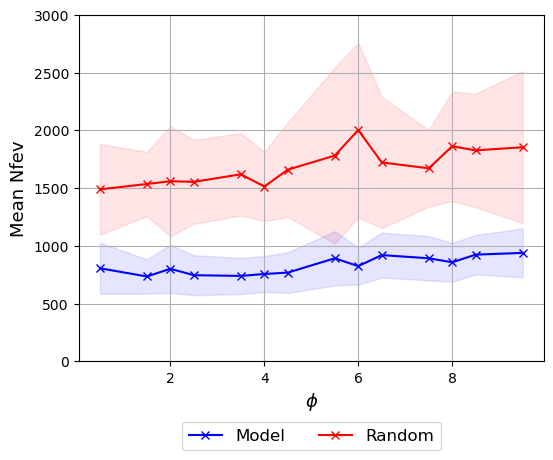

In [13]:
data_model = nfev_model[omega_norm_all==-0.6,:]
data_rand = nfev_rand[omega_norm_all==-0.6,:]

thetarange = [0., 10.]
theta_plot = thetarange[0]+0.5*(theta_norm_all[omega_norm_all==-0.6]+1)*(thetarange[1]-thetarange[0])

fig, ax = plot_nfev_params(data_model,data_rand,theta_plot,(0,3000))

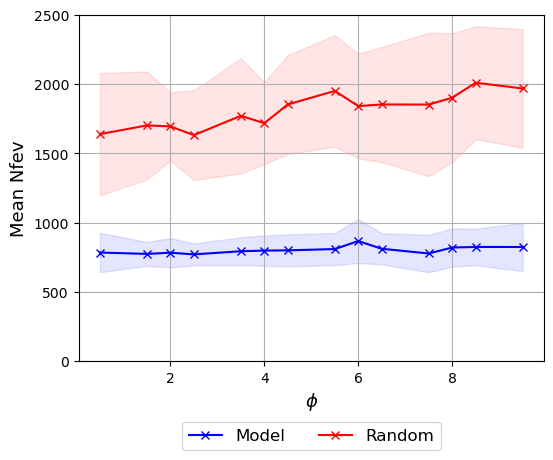

In [14]:
data_model = nfev_model[omega_norm_all==0.6,:]
data_rand = nfev_rand[omega_norm_all==0.6,:]

thetarange = [0., 10.]
theta_plot = thetarange[0]+0.5*(theta_norm_all[omega_norm_all==0.6]+1)*(thetarange[1]-thetarange[0])

fig, ax = plot_nfev_params(data_model,data_rand,theta_plot,(0,2500))

### Schwefel Models

In [15]:
norm_train = [-1. , -0.8, -0.4,  0. ,  0.4,  0.8,  1. ]
x_train_tf, c_train_tf = get_x_c_norm(norm_train, 'Schwefel')

In [16]:
norm_all = np.linspace(-1,1,21)
x_all_tf, c_all_tf = get_x_c_norm(norm_all, 'Schwefel')

In [17]:
dirname = os.path.join(PATH_TO_MODELS,'Parameters')
ll_all_train = []
ll_all_all = []
for run_no in trange(8):
    fname_load = f'_Schwefel_parameters_run{run_no}'
    model, config = load_model_json(dirname,fname_load,seed=12345678)
    ll_model = model.log_likelihood(x_train_tf, c_train_tf).numpy()
    ll_all_train.append(ll_model)
    ll_model = model.log_likelihood(x_all_tf, c_all_tf).numpy()
    ll_all_all.append(ll_model)

  0%|          | 0/8 [00:00<?, ?it/s]

In [18]:
for run, (ll_train, ll_all) in enumerate(zip(ll_all_train,ll_all_all)):
    print(f'Run{run} mean ll - train: {np.mean(ll_train):6.3f} all: {np.mean(ll_all):6.3f}')

Run0 mean ll - train: -0.030 all: -1.617
Run1 mean ll - train: -0.203 all: -2.153
Run2 mean ll - train: -0.825 all: -1.576
Run3 mean ll - train: -0.372 all: -1.325
Run4 mean ll - train: -0.129 all: -1.379
Run5 mean ll - train:  0.037 all: -1.497
Run6 mean ll - train: -0.489 all: -1.658
Run7 mean ll - train: -0.670 all: -1.365


### Schwefel Nfev Compare

In [19]:
fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_model_Schwefel_omega_1100_1800_theta_0_10.json')
with open(fname_load,'r') as f:
    data_model_all = json.load(f)

fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_random_Schwefel_omega_1100_1800_theta_0_10.json')
with open(fname_load,'r') as f:
    data_rand_all = json.load(f)

nfev_model = np.array(data_model_all['nfev'])
nfev_rand = np.array(data_rand_all['nfev'])

omega_norm_all = np.array(data_model_all['omega_norm'])
theta_norm_all = np.array(data_model_all['theta_norm'])

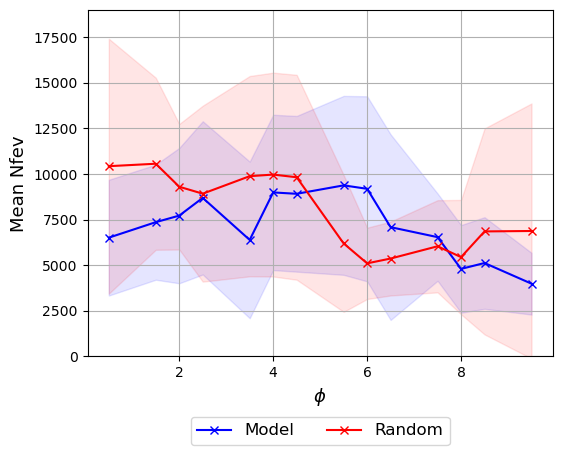

In [20]:
data_model = nfev_model[omega_norm_all==-0.6,:]
data_rand = nfev_rand[omega_norm_all==-0.6,:]

thetarange = [0., 10.]
theta_plot = thetarange[0]+0.5*(theta_norm_all[omega_norm_all==-0.6]+1)*(thetarange[1]-thetarange[0])

fig, ax = plot_nfev_params(data_model,data_rand,theta_plot,(0,19e3))

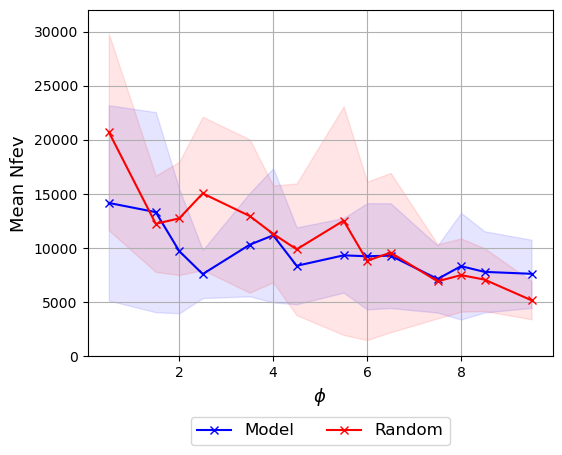

In [21]:
data_model = nfev_model[omega_norm_all==0.6,:]
data_rand = nfev_rand[omega_norm_all==0.6,:]

thetarange = [0., 10.]
theta_plot = thetarange[0]+0.5*(theta_norm_all[omega_norm_all==0.6]+1)*(thetarange[1]-thetarange[0])

fig, ax = plot_nfev_params(data_model,data_rand,theta_plot,(0,32e3))

### Whitley Models

In [22]:
norm_train = [-1. , -0.8, -0.4,  0. ,  0.4,  0.8,  1. ]
x_train_tf, c_train_tf = get_x_c_norm(norm_train, 'Whitley')

In [23]:
norm_all = np.linspace(-1,1,21)
x_all_tf, c_all_tf = get_x_c_norm(norm_all, 'Whitley')

In [24]:
dirname = os.path.join(PATH_TO_MODELS,'Parameters')
ll_all_train = []
ll_all_all = []
for run_no in trange(8):
    fname_load = f'_Whitley_parameters_run{run_no}'
    model, config = load_model_json(dirname,fname_load,seed=12345678)
    ll_model = model.log_likelihood(x_train_tf, c_train_tf).numpy()
    ll_all_train.append(ll_model)
    ll_model = model.log_likelihood(x_all_tf, c_all_tf).numpy()
    ll_all_all.append(ll_model)

  0%|          | 0/8 [00:00<?, ?it/s]

In [25]:
for run, (ll_train, ll_all) in enumerate(zip(ll_all_train,ll_all_all)):
    print(f'Run{run} mean ll - train: {np.mean(ll_train):6.3f} all: {np.mean(ll_all):6.3f}')

Run0 mean ll - train: -1.382 all: -1.649
Run1 mean ll - train: -1.534 all: -2.178
Run2 mean ll - train: -0.424 all: -0.781
Run3 mean ll - train: -0.482 all: -1.587
Run4 mean ll - train: -1.306 all: -1.320
Run5 mean ll - train: -0.934 all: -0.960
Run6 mean ll - train: -0.375 all: -0.561
Run7 mean ll - train: -0.421 all: -1.767


### Whitley Nfev Compare

In [26]:
fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_model_Whitley_omega_0p2_0p3_theta_0_10.json')
with open(fname_load,'r') as f:
    data_model_all = json.load(f)

fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_random_Whitley_omega_0p2_0p3_theta_0_10.json')
with open(fname_load,'r') as f:
    data_rand_all = json.load(f)

nfev_model = np.array(data_model_all['nfev'])
nfev_rand = np.array(data_rand_all['nfev'])

omega_norm_all = np.array(data_model_all['omega_norm'])
theta_norm_all = np.array(data_model_all['theta_norm'])

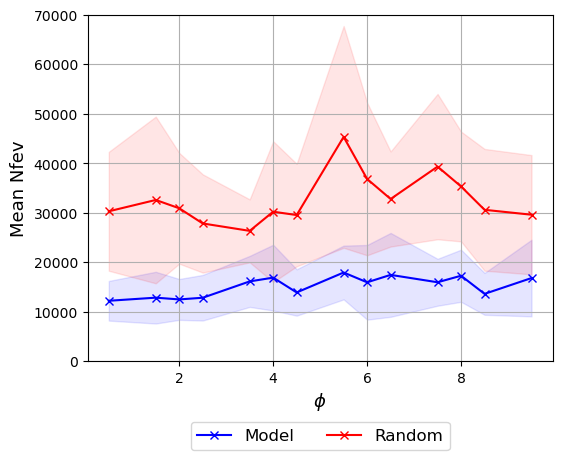

In [27]:
data_model = nfev_model[omega_norm_all==-0.6,:]
data_rand = nfev_rand[omega_norm_all==-0.6,:]

thetarange = [0., 10.]
theta_plot = thetarange[0]+0.5*(theta_norm_all[omega_norm_all==-0.6]+1)*(thetarange[1]-thetarange[0])

fig, ax = plot_nfev_params(data_model,data_rand,theta_plot,(0,70e3))

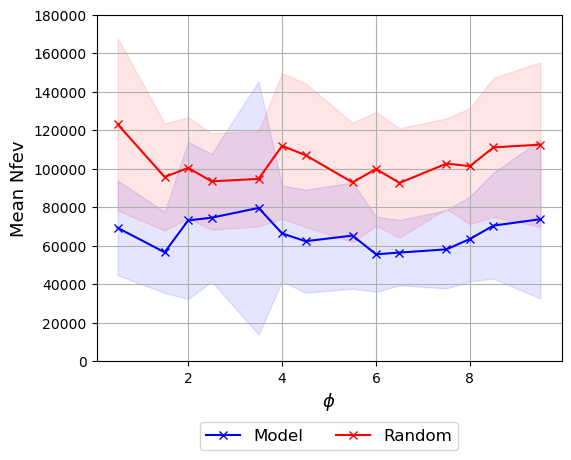

In [28]:
data_model = nfev_model[omega_norm_all==0.6,:]
data_rand = nfev_rand[omega_norm_all==0.6,:]

thetarange = [0., 10.]
theta_plot = thetarange[0]+0.5*(theta_norm_all[omega_norm_all==0.6]+1)*(thetarange[1]-thetarange[0])

fig, ax = plot_nfev_params(data_model,data_rand,theta_plot,(0,180e3))

### CR5BP Models

In [29]:
norm_train = np.linspace(-1,1,9)
x_train_tf, c_train_tf = get_x_c_norm(norm_train, 'CR5BP')

In [30]:
norm_all = np.linspace(-1,1,21)
x_all_tf, c_all_tf = get_x_c_norm(norm_all, 'CR5BP')

In [31]:
dirname = os.path.join(PATH_TO_MODELS,'Parameters')
ll_all_train = []
ll_all_all = []
for run_no in trange(8):
    fname_load = f'_CR5BP_parameters_run{run_no}'
    model, config = load_model_json(dirname,fname_load,seed=12345678)
    ll_model = model.log_likelihood(x_train_tf, c_train_tf).numpy()
    ll_all_train.append(ll_model)
    ll_model = model.log_likelihood(x_all_tf, c_all_tf).numpy()
    ll_all_all.append(ll_model)

  0%|          | 0/8 [00:00<?, ?it/s]

In [32]:
for run, (ll_train, ll_all) in enumerate(zip(ll_all_train,ll_all_all)):
    print(f'Run{run} mean ll - train: {np.mean(ll_train):6.3f} all: {np.mean(ll_all):6.3f}')

Run0 mean ll - train:  2.515 all:  0.709
Run1 mean ll - train:  3.556 all: -2.588
Run2 mean ll - train:  2.796 all: -4.633
Run3 mean ll - train:  2.372 all: -0.003
Run4 mean ll - train: -32.054 all: -30.100
Run5 mean ll - train:  3.754 all: -0.744
Run6 mean ll - train:  3.087 all:  1.236
Run7 mean ll - train:  3.372 all: -1.865


### CR5BP Nfev Compare

In [8]:
fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_model_CR5BP_mu_0p005_0p995.json')
with open(fname_load,'r') as f:
    data_model_all = json.load(f)

fname_load = os.path.join(PATH_TO_DATA,
                          'Parameters',
                          'nfev_random_CR5BP_mu_0p005_0p995.json')
with open(fname_load,'r') as f:
    data_rand_all = json.load(f)

nfev_model = np.array(data_model_all['nfev'])
nfev_rand = np.array(data_rand_all['nfev'])

mu_norm_all = np.array(data_model_all['mu_norm'])

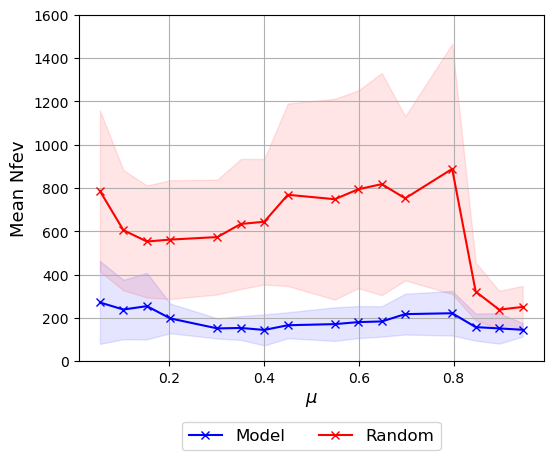

In [9]:
data_model = nfev_model[:-10,:]
data_rand = nfev_rand[:-10,:]

murange = [0.005,0.995]
mu_plot = murange[0]+0.5*(mu_norm_all[:-10]+1)*(murange[1]-murange[0])

fig, ax = plot_nfev_params(data_model,data_rand,mu_plot,(0,1600),xlabel=r'$\mu$')

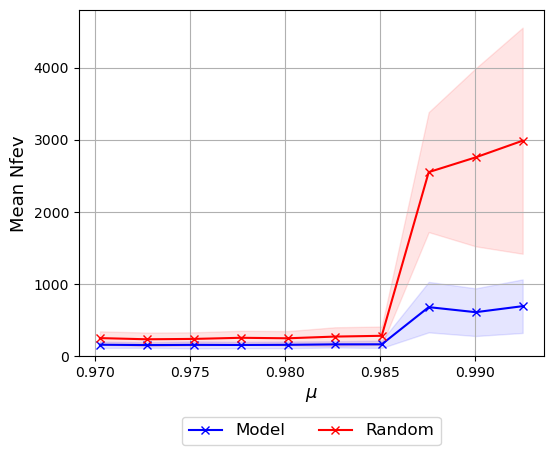

In [10]:
data_model = nfev_model[-10:,:]
data_rand = nfev_rand[-10:,:]

murange = [0.005,0.995]
mu_plot = murange[0]+0.5*(mu_norm_all[-10:]+1)*(murange[1]-murange[0])

fig, ax = plot_nfev_params(data_model,data_rand,mu_plot,(0,4800),xlabel=r'$\mu$')

## Class Labels Training Data

In [5]:
def get_minima_fvals(norm_all, distname):
    min_all = []
    fvals_all = []
    params_all = []
    thetarange = [0., 10.]
    if distname=='Rastrigin':
        omrange = [3.5,4.5]
        f_get_min = lambda om, t: get_min_rot_rast(om,t,fvals=True)
    elif distname=='Schwefel':
        omrange = [1100,1800]
        dx = np.array([1.,-1.])
        f_get_min = lambda om, t: get_min_rot_schwefel(om,t,dx=dx,min_x=10./om,fvals=True)
    elif distname=='Whitley':
        omrange = [0.2, 0.3]
        f_get_min = lambda om, t: get_min_rot_whitley(om,t,fvals=True)
    for n1,n2 in product(norm_all,norm_all):
        omega = omrange[0] + 0.5*(n1+1)*(omrange[1]-omrange[0])
        theta = thetarange[0] + 0.5*(n2+1)*(thetarange[1]-thetarange[0])
        min_new, fvals_new = f_get_min(omega, theta*np.pi/180.)
        min_all.extend([m for m in min_new])
        fvals_all.extend([fval for fval in fvals_new])
        params_all.extend([[n1,n2]]*min_new.shape[0])
    min_fvals_params = np.hstack(
        [min_all, np.array(fvals_all).reshape(-1,1), params_all]
    )
    return min_fvals_params

In [6]:
from scripts.run_test_labels import get_omega_theta, calc_min_class_distance, calc_eq_class_distance

def get_random_min_distances(distname,
                             N_samp = 1000,
                             seed = 12345678):
    rng = np.random.default_rng(seed=seed)
    x_samp = rng.uniform(low=[-1]*4,high=[1]*4,size=(N_samp,4))
    omega_samp, theta_samp = get_omega_theta(x_samp, distname=distname)
    dist_min = []
    for x,omega,theta in tqdm(zip(x_samp[:,:2],omega_samp,theta_samp),total=N_samp):
        dist_min.append(calc_min_class_distance(x,omega,theta,distname=distname))
    return dist_min

def get_random_eq_distances(N_samp = 1000,
                            seed = 12345678):
    rng = np.random.default_rng(seed=seed)
    x_samp = rng.uniform(low=[-0.8]*3,high=[0.8]*3,size=(N_samp,3))
    min_dist_all, mu_samp_all = calc_eq_class_distance(x_samp, mindir='mindata', show_progress=True)
    return min_dist_all, mu_samp_all

### Saving all minima

In [7]:
norm_all = np.arange(-10,11)/10.

In [8]:
min_fvals_all = get_minima_fvals(norm_all,'Rastrigin')
min_df = pd.DataFrame(data=min_fvals_all,columns=['x','y','fval','omega_norm','theta_norm'])
min_df.describe()

,x,y,fval,omega_norm,theta_norm
count,2.840100e+04,2.840100e+04,28401.000000,28401.000000,28401.000000
mean,9.381836e-19,6.645467e-19,0.665384,0.107222,-0.003056
std,5.767145e-01,5.767145e-01,0.419746,0.596635,0.606401
min,-9.999339e-01,-9.999339e-01,0.000000,-1.000000,-1.000000
25%,-4.997506e-01,-4.997506e-01,0.304737,-0.400000,-0.500000
50%,0.000000e+00,0.000000e+00,0.640715,0.200000,0.000000
75%,4.997506e-01,4.997506e-01,0.963442,0.600000,0.500000
max,9.999339e-01,9.999339e-01,1.999367,1.000000,1.000000


In [9]:
dirname_save = os.path.join(PATH_TO_DATA,'Labels/')
fname_save = 'minfvals_Rastrigin_omega_3p5_4p5_theta_0_10_all'

min_save_tf = tf.constant(min_fvals_all,dtype=tf.float32)
save_tensor_data(min_save_tf, dirname=dirname_save, fname=fname_save)

min_df.to_csv(os.path.join(dirname_save,fname_save)+'.csv',index=False)

In [10]:
min_fvals_all = get_minima_fvals(norm_all,'Schwefel')
min_df = pd.DataFrame(data=min_fvals_all,columns=['x','y','fval','omega_norm','theta_norm'])
min_df.describe()

,x,y,fval,omega_norm,theta_norm
count,22175.000000,22175.000000,22175.000000,22175.000000,22175.000000
mean,-0.201407,-0.255521,-1700.184513,0.094643,-0.079892
std,0.599473,0.581871,1320.513371,0.600390,0.605683
min,-0.999834,-0.999934,-6691.605768,-1.000000,-1.000000
25%,-0.749563,-0.772402,-2566.107036,-0.400000,-0.600000
50%,-0.310662,-0.385225,-1658.099810,0.100000,-0.100000
75%,0.290173,0.197926,-671.137923,0.600000,0.400000
max,0.999680,0.999735,710.695836,1.000000,1.000000


In [11]:
dirname_save = os.path.join(PATH_TO_DATA,'Labels/')
fname_save = 'minfvals_Schwefel_omega_1100_1800_theta_0_10_all'

min_save_tf = tf.constant(min_fvals_all,dtype=tf.float32)
save_tensor_data(min_save_tf, dirname=dirname_save, fname=fname_save)

min_df.to_csv(os.path.join(dirname_save,fname_save)+'.csv',index=False)

In [12]:
min_fvals_all = get_minima_fvals(norm_all,'Whitley')
min_df = pd.DataFrame(data=min_fvals_all,columns=['x','y','fval','omega_norm','theta_norm'])
min_df.describe()

,x,y,fval,omega_norm,theta_norm
count,33428.000000,33428.000000,3.342800e+04,33428.000000,33428.000000
mean,0.058862,0.105194,4.794499e-01,0.274198,-0.002926
std,0.699333,0.665493,5.249921e-01,0.561158,0.605188
min,-0.999969,-0.999986,5.873080e-14,-1.000000,-1.000000
25%,-0.649507,-0.552144,9.864672e-02,-0.100000,-0.500000
50%,0.200516,0.247447,2.860755e-01,0.400000,0.000000
75%,0.755109,0.744092,7.102564e-01,0.800000,0.500000
max,0.999940,0.999971,3.649928e+00,1.000000,1.000000


In [13]:
dirname_save = os.path.join(PATH_TO_DATA,'Labels/')
fname_save = 'minfvals_Whitley_omega_0p2_0p3_theta_0_10_all'

min_save_tf = tf.constant(min_fvals_all,dtype=tf.float32)
save_tensor_data(min_save_tf, dirname=dirname_save, fname=fname_save)

min_df.to_csv(os.path.join(dirname_save,fname_save)+'.csv',index=False)

In [14]:
norm_all = np.arange(-20,21)/20.
min_mu, c_label = get_minima_classes_cr5bp(norm_all, mu_min=0.001, mu_max=0.05)
min_mu_c_all = np.hstack([min_mu,c_label])
min_df = pd.DataFrame(data=min_mu_c_all,columns=['x','y','mu_norm','c0','c1'])
min_df.describe()

,x,y,mu_norm,c0,c1
count,3.690000e+02,3.690000e+02,369.000000,369.000000,369.000000
mean,-2.045939e-17,-8.123583e-18,0.000000,0.853659,0.146341
std,4.185688e-01,4.185688e-01,0.592411,0.353928,0.353928
min,-5.842007e-01,-6.390463e-01,-1.000000,0.000000,0.000000
25%,-3.457837e-01,-4.224510e-01,-0.500000,1.000000,0.000000
50%,-2.265747e-01,0.000000e+00,0.000000,1.000000,0.000000
75%,2.916596e-01,4.224510e-01,0.500000,1.000000,0.000000
max,7.379071e-01,6.390463e-01,1.000000,1.000000,1.000000


In [15]:
dirname_save = os.path.join(PATH_TO_DATA,'Labels/')
fname_save = 'minclass_CR5BP_mu_0p001_0p05_all'

min_save_tf = tf.constant(min_mu_c_all,dtype=tf.float32)
save_tensor_data(min_save_tf, dirname=dirname_save, fname=fname_save)

min_df.to_csv(os.path.join(dirname_save,fname_save)+'.csv',index=False)

### Rastrigin Data

In [7]:
dist_rand = get_random_min_distances('Rastrigin',N_samp=10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

In [8]:
dtest_rand = np.array(dist_rand).copy()
dtest_rand[dtest_rand<0] = 100.
rand_classes = pd.Series(np.argmin(dtest_rand,axis=-1))
rand_classes.value_counts().map(lambda x:x/100.).sort_index()

0    35.08
1    37.08
2    27.84
dtype: float64

In [9]:
fname_load = 'minfvals_Rastrigin_omega_3p5_4p5_theta_0_10_all'
min_fvals_all = load_tensor_data(os.path.join(PATH_TO_DATA,'Labels',fname_load)).numpy()
min_all = min_fvals_all[:,:2]
params_all = min_fvals_all[:,3:]

In [10]:
bins = [-0.1, 0.45, 0.9, 2.]
c_all = fvals_to_labels(min_fvals_all[:,2],bins)
100.*np.sum(c_all,axis=0)/c_all.shape[0]

array([34.678356, 36.083237, 29.238407], dtype=float32)

In [11]:
norm_all = [-1., -0.8, -0.4, 0., 0.4, 0.8, 1.]
norm_omega_lab = [-1., -0.4, 0.4, 1.]

data_ul = []
data_lab = []
data_full = []
for n_omega, n_theta in product(norm_all, norm_all):
    filt = (np.abs(params_all[:,0]-n_omega)<0.01)&(np.abs(params_all[:,1]-n_theta)<0.01)
    data_new = np.hstack([
        min_all[filt,:],
        params_all[filt,:],
        c_all[filt,:]
    ])
    data_full.extend([d for d in data_new])
    if n_omega in norm_omega_lab:
        data_lab.extend([d for d in data_new])
    else:
        data_ul.extend([d[:4] for d in data_new])
data_ul = np.array(data_ul)
print(data_ul.shape)
data_lab = np.array(data_lab)
print(data_lab.shape)
data_full = np.array(data_full)
print(data_full.shape)

(1369, 4)
(1808, 7)
(3177, 7)


In [12]:
psamp_ul = sample_with_noise(data_ul, 7, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 87654321, 
                             seed_samp = 987654321)
psamp_lab = sample_with_noise(data_lab, 6, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 12345678, 
                             seed_samp = 123456789)
psamp_full = sample_with_noise(data_full, 3, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 12345678, 
                             seed_samp = 123456789)

N min 1369 min sampled 1369
N min 1808 min sampled 1808
N min 3177 min sampled 3177


In [ ]:
columns = ['x','y','omega_norm','theta_norm','c0','c1','c2']
for psamp_data, lname in zip([psamp_ul, psamp_lab, psamp_full],['unlabel','label','fullysup']):
    psave_tf = tf.constant(psamp_data,dtype=tf.float32)
    fname_save = f'traindata_{lname}_Rastrigin_omega_3p5_4p5_theta_0_10_n7'
    save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Labels'),fname=fname_save)

    df_save = pd.DataFrame(data=psamp_data,columns=columns[:psamp_data.shape[1]])
    fname_csv = fname_save+'.csv'
    df_save.to_csv(os.path.join(PATH_TO_DATA,'Labels',fname_csv),index=False)

### Schwefel Data

In [7]:
dist_rand = get_random_min_distances('Schwefel',N_samp=10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

In [8]:
dtest_rand = np.array(dist_rand).copy()
dtest_rand[dtest_rand<0] = 100.
rand_classes = pd.Series(np.argmin(dtest_rand,axis=-1))
rand_classes.value_counts().map(lambda x:x/100.).sort_index()

0    54.68
1    27.55
2    17.77
dtype: float64

In [9]:
fname_load = 'minfvals_Schwefel_omega_1100_1800_theta_0_10_all'
min_fvals_all = load_tensor_data(os.path.join(PATH_TO_DATA,'Labels',fname_load)).numpy()
min_all = min_fvals_all[:,:2]
params_all = min_fvals_all[:,3:]

In [10]:
bins = [-7e3, -2e3, -1e3, 1e3]
c_all = fvals_to_labels(min_fvals_all[:,2],bins)
100.*np.sum(c_all,axis=0)/c_all.shape[0]

array([37.28072 , 27.382187, 35.33709 ], dtype=float32)

In [11]:
norm_all = [-1., -0.8, -0.4, 0., 0.4, 0.8, 1.]
norm_omega_lab = [-1., -0.4, 0.4, 1.]

data_ul = []
data_lab = []
data_full = []
for n_omega, n_theta in product(norm_all, norm_all):
    filt = (np.abs(params_all[:,0]-n_omega)<0.01)&(np.abs(params_all[:,1]-n_theta)<0.01)
    data_new = np.hstack([
        min_all[filt,:],
        params_all[filt,:],
        c_all[filt,:]
    ])
    data_full.extend([d for d in data_new])
    if n_omega in norm_omega_lab:
        data_lab.extend([d for d in data_new])
    else:
        data_ul.extend([d[:4] for d in data_new])
data_ul = np.array(data_ul)
print(data_ul.shape)
data_lab = np.array(data_lab)
print(data_lab.shape)
data_full = np.array(data_full)
print(data_full.shape)

(1083, 4)
(1411, 7)
(2494, 7)


In [12]:
psamp_ul = sample_with_noise(data_ul, 9, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 87654321, 
                             seed_samp = 987654321)
psamp_lab = sample_with_noise(data_lab, 7, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 12345678, 
                             seed_samp = 123456789)
psamp_full = sample_with_noise(data_full, 4, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 12345678, 
                             seed_samp = 123456789)

N min 1083 min sampled 1083
N min 1411 min sampled 1411
N min 2494 min sampled 2494


In [ ]:
columns = ['x','y','omega_norm','theta_norm','c0','c1','c2']
for psamp_data, lname in zip([psamp_ul, psamp_lab, psamp_full],['unlabel','label','fullysup']):
    psave_tf = tf.constant(psamp_data,dtype=tf.float32)
    fname_save = f'traindata_{lname}_Schwefel_omega_1100_1800_theta_0_10_n7'
    save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Labels'),fname=fname_save)

    df_save = pd.DataFrame(data=psamp_data,columns=columns[:psamp_data.shape[1]])
    fname_csv = fname_save+'.csv'
    df_save.to_csv(os.path.join(PATH_TO_DATA,'Labels',fname_csv),index=False)

### Whitley Data

In [7]:
dist_rand = get_random_min_distances('Whitley',N_samp=10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

In [8]:
dtest_rand = np.array(dist_rand).copy()
dtest_rand[dtest_rand<0] = 100.
rand_classes = pd.Series(np.argmin(dtest_rand,axis=-1))
rand_classes.value_counts().map(lambda x:x/100.).sort_index()

0    75.57
1    16.94
2     7.49
dtype: float64

In [9]:
fname_load = 'minfvals_Whitley_omega_0p2_0p3_theta_0_10_all'
min_fvals_all = load_tensor_data(os.path.join(PATH_TO_DATA,'Labels',fname_load)).numpy()
min_all = min_fvals_all[:,:2]
params_all = min_fvals_all[:,3:]

In [10]:
bins = [-1, 0.15, 0.5, 5]
c_all = fvals_to_labels(min_fvals_all[:,2],bins)
100.*np.sum(c_all,axis=0)/c_all.shape[0]

array([32.73902, 32.83475, 34.42623], dtype=float32)

In [11]:
norm_all = [-1., -0.8, -0.4, 0., 0.4, 0.8, 1.]
norm_omega_lab = [-1., -0.4, 0.4, 1.]

data_ul = []
data_lab = []
data_full = []
for n_omega, n_theta in product(norm_all, norm_all):
    filt = (np.abs(params_all[:,0]-n_omega)<0.01)&(np.abs(params_all[:,1]-n_theta)<0.01)
    data_new = np.hstack([
        min_all[filt,:],
        params_all[filt,:],
        c_all[filt,:]
    ])
    data_full.extend([d for d in data_new])
    if n_omega in norm_omega_lab:
        data_lab.extend([d for d in data_new])
    else:
        data_ul.extend([d[:4] for d in data_new])
data_ul = np.array(data_ul)
print(data_ul.shape)
data_lab = np.array(data_lab)
print(data_lab.shape)
data_full = np.array(data_full)
print(data_full.shape)

(1616, 4)
(2220, 7)
(3836, 7)


In [12]:
psamp_ul = sample_with_noise(data_ul, 6, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 87654321, 
                             seed_samp = 987654321)
psamp_lab = sample_with_noise(data_lab, 5, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 12345678, 
                             seed_samp = 123456789)

N min 1616 min sampled 1616
N min 2220 min sampled 2220


In [13]:
rng_noise = np.random.default_rng(seed=12345678)
noise_minall = rng_noise.normal(loc=[0.]*7, scale=[1e-3,1e-3]+[0.]*5, size=(data_full.shape[0],7))
psamp_data_minall = data_full+noise_minall
rng_noise.shuffle(psamp_data_minall,axis=0)

noise_all = rng_noise.normal(loc=[0.]*7, scale=[1e-3,1e-3]+[0.]*5, size=(data_full.shape[0],2,7))
psamp_add = (np.expand_dims(data_full,1) + noise_all).reshape(-1,7)
rng_samp = np.random.default_rng(seed=7654321)
psamp_data_add = rng_samp.choice(psamp_add,size=2**13+1024-3836,replace=False)

psamp_full = np.vstack([psamp_data_minall,psamp_data_add])[:2**13+1024,:]

mindiff_all = np.linalg.norm(np.expand_dims(psamp_full,0)-np.expand_dims(data_full,1),axis=-1)
min_true = np.any(mindiff_all[:2**13,:]<0.01,axis=-1)
del mindiff_all
print(f'N min {data_full.shape[0]} min sampled {np.sum(min_true)}')

N min 3836 min sampled 3836


In [ ]:
columns = ['x','y','omega_norm','theta_norm','c0','c1','c2']
for psamp_data, lname in zip([psamp_ul, psamp_lab, psamp_full],['unlabel','label','fullysup']):
    psave_tf = tf.constant(psamp_data,dtype=tf.float32)
    fname_save = f'traindata_{lname}_Whitley_omega_0p2_0p3_theta_0_10_n7'
    save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Labels'),fname=fname_save)

    df_save = pd.DataFrame(data=psamp_data,columns=columns[:psamp_data.shape[1]])
    fname_csv = fname_save+'.csv'
    df_save.to_csv(os.path.join(PATH_TO_DATA,'Labels',fname_csv),index=False)

### CR5BP Data

In [7]:
dist_rand, mu_rand = get_random_eq_distances(N_samp=10000)

100%|█████████████████████████████████████| 10000/10000 [04:44<00:00, 35.10it/s]


In [8]:
dtest_rand = np.array(dist_rand).copy()
dtest_rand[dtest_rand<0] = 100.
rand_classes = pd.Series(np.argmin(dtest_rand,axis=-1))
rand_classes.value_counts().map(lambda x:x/100.).sort_index()

0    81.44
1    18.56
dtype: float64

In [9]:
fname_load = 'minclass_CR5BP_mu_0p001_0p05_all'
min_class_all = load_tensor_data(os.path.join(PATH_TO_DATA,'Labels',fname_load)).numpy()

In [11]:
c_all = min_class_all[:,-2:]
100.*np.sum(c_all,axis=0)/c_all.shape[0]

array([85.36585 , 14.634147], dtype=float32)

In [12]:
norm_mu_lab = [-1., -0.3, 0.3, 1.]
norm_mu_ul = [-0.8, -0.6, -0.4, -0.2,  0. , 0.2, 0.4, 0.6, 0.8]
norm_mu_full = [-1., -0.8, -0.4, 0., 0.4, 0.8, 1.]
norm_all = [-1., -0.8, -0.6, -0.4, -0.3, -0.2, 0., 0.2, 0.3, 0.4, 0.6, 0.8, 1.]

data_ul = []
data_lab = []
data_full = []
for n_mu in norm_all:
    filt = np.abs(min_class_all[:,2]-n_mu)<0.01
    data_new = min_class_all[filt,:]
    if n_mu in norm_mu_ul:
        data_ul.extend([d[:3] for d in data_new])
    if n_mu in norm_mu_lab:
        data_lab.extend([d for d in data_new])
    if n_mu in norm_mu_full:
        data_full.extend([d for d in data_new])
data_ul = np.array(data_ul)
print(data_ul.shape)
data_lab = np.array(data_lab)
print(data_lab.shape)
data_full = np.array(data_full)
print(data_full.shape)

(81, 3)
(36, 5)
(63, 5)


In [13]:
psamp_ul = sample_with_noise(data_ul, 114, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 87654321, 
                             seed_samp = 987654321)
psamp_lab = sample_with_noise(data_lab, 256, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 12345678, 
                             seed_samp = 123456789)
psamp_full = sample_with_noise(data_full, 147, 2**13+1024, 
                             N_check = 2**13, 
                             seed_noise = 12345678, 
                             seed_samp = 123456789)

N min 81 min sampled 81
N min 36 min sampled 36
N min 63 min sampled 63


In [ ]:
columns = ['x','y','mu_norm','c0','c1']
for psamp_data, lname in zip([psamp_ul, psamp_lab, psamp_full],['unlabel','label','fullysup']):
    psave_tf = tf.constant(psamp_data,dtype=tf.float32)
    fname_save = f'traindata_{lname}_CR5BP_mu_0p001_0p05'
    save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Labels'),fname=fname_save)

    df_save = pd.DataFrame(data=psamp_data,columns=columns[:psamp_data.shape[1]])
    fname_csv = fname_save+'.csv'
    df_save.to_csv(os.path.join(PATH_TO_DATA,'Labels',fname_csv),index=False)

## Class Labels Results

In [5]:
def get_train_test_data(distname):
    """Training/test dataset defined by values of parameters"""
    
    if distname=='CR5BP':
        fname_load = 'minclass_CR5BP_mu_0p001_0p05_all'
        min_class_all = load_tensor_data(os.path.join(PATH_TO_DATA,'Labels',fname_load)).numpy()
        norm_mu_lab = [-1., -0.3, 0.3, 1.]
        norm_mu_ul = [-0.8, -0.6, -0.4, -0.2,  0. , 0.2, 0.4, 0.6, 0.8]
        norm_all = np.arange(-20,21)/20.
        
        data_train_ul = []
        data_train_lab = []
        data_test = []
        for n_mu in norm_all:
            filt = np.abs(min_class_all[:,2]-n_mu)<0.01
            data_new = min_class_all[filt,:]
            if n_mu in norm_mu_ul:
                data_train_ul.extend([d for d in data_new])
            elif n_mu in norm_mu_lab:
                data_train_lab.extend([d for d in data_new])
            else:
                data_test.extend([d for d in data_new])
    else:
        if distname=='Rastrigin':
            fname_load = 'minfvals_Rastrigin_omega_3p5_4p5_theta_0_10_all'
            bins = [-0.1, 0.45, 0.9, 2.]
        elif distname=='Schwefel':
            fname_load = 'minfvals_Schwefel_omega_1100_1800_theta_0_10_all'
            bins = [-7e3, -2e3, -1e3, 1e3]
        elif distname=='Whitley':
            fname_load = 'minfvals_Whitley_omega_0p2_0p3_theta_0_10_all'
            bins = [-1, 0.15, 0.5, 5]
        min_fvals_all = load_tensor_data(os.path.join(PATH_TO_DATA,'Labels',fname_load)).numpy()
        min_all = min_fvals_all[:,:2]
        params_all = min_fvals_all[:,3:]
        c_all = fvals_to_labels(min_fvals_all[:,2],bins)
        norm_all = np.arange(-10,11)/10.
        norm_full = [-1., -0.8, -0.4, 0., 0.4, 0.8, 1.]
        norm_omega_lab = [-1., -0.4, 0.4, 1.]
        
        data_train_ul = []
        data_train_lab = []
        data_test = []
        for n_omega, n_theta in product(norm_all, norm_all):
            filt = (np.abs(params_all[:,0]-n_omega)<0.01)&(np.abs(params_all[:,1]-n_theta)<0.01)
            data_new = np.hstack([
                min_all[filt,:],
                params_all[filt,:],
                c_all[filt,:]
            ])
            if n_omega in norm_full and n_theta in norm_full:
                if n_omega in norm_omega_lab:
                    data_train_lab.extend([d for d in data_new])
                else:
                    data_train_ul.extend([d for d in data_new])
            else:
                data_test.extend([d for d in data_new])
    
    data_ul_tf = tf.constant(data_train_ul,dtype=tf.float32)
    data_lab_tf = tf.constant(data_train_lab,dtype=tf.float32)
    data_test_tf = tf.constant(data_test,dtype=tf.float32)
    return data_ul_tf, data_lab_tf, data_test_tf

In [6]:
def train_test_ll(distname, N_run=8):
    dim = 3 if distname=='CR5BP' else 4
    data_train_ul, data_train_lab, data_test = get_train_test_data(distname)
    scenario_all = ['semisup','fullysup','partsup']
    dirname = os.path.join(PATH_TO_MODELS,'Labels')
    ll_all = {}
    for scenario in scenario_all:
        ll_all[scenario] = {
            'train': [],
            'train_ul': [],
            'test': []
        }
        if scenario=='fullysup':
            xtrain = tf.concat([data_train_lab[:,:dim],data_train_ul[:,:dim]],axis=0)
            ctrain = tf.concat([data_train_lab[:,dim:],data_train_ul[:,dim:]],axis=0)
            xtest = data_test[:,:dim]
            ctest = data_test[:,dim:]
        elif scenario=='partsup':
            xtrain = data_train_lab[:,:dim]
            ctrain = data_train_lab[:,dim:]
            xtest = tf.concat([data_train_ul[:,:dim],data_test[:,:dim]],axis=0)
            ctest = tf.concat([data_train_ul[:,dim:],data_test[:,dim:]],axis=0)
        else:
            xtrain, ctrain = data_train_lab[:,:dim], data_train_lab[:,dim:]
            xtrain_ul, ctrain_ul = data_train_ul[:,:dim], data_train_ul[:,dim:]
            xtest, ctest = data_test[:,:dim], data_test[:,dim:]
        for run_no in trange(N_run):
            fname_load = f'_{distname}_{scenario}_run{run_no}'
            model, _ = load_model_json(dirname,fname_load)
            ll_train = model.log_likelihood(xtrain, ctrain).numpy()
            ll_all[scenario]['train'].append(ll_train)
            ll_test = model.log_likelihood(xtest, ctest).numpy()
            ll_all[scenario]['test'].append(ll_test)
            if scenario=='semisup':
                ll_train_ul = model.log_likelihood(xtrain_ul, ctrain_ul).numpy()
                ll_all[scenario]['train_ul'].append(ll_train_ul)
    return ll_all

def calc_acc_run(dist_run):
    dist_test = dist_run.copy()
    dist_test[dist_test<0] = 100.
    dist_class_all = np.argmin(dist_test,axis=-1)
    conmat = np.array([np.sum(dist_class_all==i,axis=-1) for i in range(dist_run.shape[-1])])
    return np.diag(conmat)/np.sum(conmat,axis=0)

In [7]:
def calc_dist_miss(data_run, ind_best=None):
    acc_runs = np.array([calc_acc_run(d) for d in data_load])
    if ind_best is None:
        ind_best = np.argmax(np.mean(acc_runs,axis=-1))
    
    dist_best = data_load[ind_best,...]
    p_inval = np.sum(dist_best<0,axis=1).T
    dist_best[dist_best<0] = 100.
    dist_class_all = np.argmin(dist_best,axis=-1)
    N_c = dist_best.shape[0]
    conmat = np.array([np.sum(dist_class_all==i,axis=-1) for i in range(N_c)])
    
    miss_dist = np.zeros((N_c,N_c))
    mean_dist = np.zeros((N_c,N_c))
    # j - pred ind
    # i - true ind
    for i,j in product(range(N_c),range(N_c)):
        dist_ij = dist_best[j,dist_class_all[j,:]==i,j] #distance from sample j where class is i to point j
        miss_dist[i,j] = np.mean(dist_ij[dist_ij<100.]) if np.sum(dist_ij<100.)>0 else np.nan

        dist_tp_i2j = dist_best[i,dist_class_all[i,:]==i,j] #distance from sample i with correct label to point j
        mean_dist[i,j] = np.mean(dist_tp_i2j[dist_tp_i2j<100.]) if np.sum(dist_tp_i2j<100.)>0 else np.nan
    return miss_dist, mean_dist, conmat, p_inval

In [8]:
def plot_conmats(conmat_all):
    dim = conmat_all['fullysup'].shape[0]
    fig, axs = plt.subplots(1,3,figsize=(12,4))
    titles = {
        'fullysup': 'Supervised n7',
        'partsup': 'Supervised n4',
        'semisup': 'Semi-supervised'
    }
    for ax, k in zip(axs, conmat_all):
        conmat = conmat_all[k]
        conmat_dist_norm = conmat/np.sum(conmat,axis=0).reshape(1,-1)
        im = ax.imshow(conmat_dist_norm, vmin=0, vmax=1, cmap='inferno')
        ax.set_xlabel('Predicted Sample Class',fontsize=11)
        
        ax.set_xticks(range(dim), labels=range(dim))
        ax.set_yticks(range(dim), labels=range(dim))
        ax.xaxis.tick_top()
        ax.xaxis.set_label_position('top')
        
        for i,j in product(range(dim),range(dim)):
            c = conmat[i, j]
            color = 'w' if c<700 else 'k'
            text = ax.text(j, i, c,
                           ha="center", va="center", color=color)
        
        n_tot = np.sum(conmat,axis=0)
        for i in range(dim):
            ax.text(i,dim-0.3,f'{n_tot[i]:.0f}',fontsize=11,ha='center')
        ax.text((dim-1.)/2.,dim,titles[k],
                horizontalalignment='center',
                fontsize=13)
    axs[0].set_ylabel('Nearest Minimum Class',fontsize=11)
    axs[0].text(-1,dim-0.3,'Total',fontsize=11)
    return fig, axs

In [9]:
def plot_diffmats(diffmat_all):
    dim = diffmat_all['fullysup'].shape[0]
    fig, axs = plt.subplots(1,3,figsize=(12,4))
    titles = {
        'fullysup': 'Supervised n7',
        'partsup': 'Supervised n4',
        'semisup': 'Semi-supervised'
    }
    for ax, k in zip(axs, diffmat_all):
        diffmat = diffmat_all[k].copy()
        diffmat[np.isnan(diffmat)] = 0.
        vmax = np.max(np.abs(diffmat))
        im = ax.imshow(diffmat, vmin=-vmax, vmax=vmax, cmap='RdBu')
        ax.set_xlabel('Predicted Sample Class',fontsize=11)
        
        ax.set_xticks(range(dim), labels=range(dim))
        ax.set_yticks(range(dim), labels=range(dim))
        ax.xaxis.tick_top()
        ax.xaxis.set_label_position('top')
        
        for i,j in product(range(dim),range(dim)):
            if i==j:
                continue
            c = diffmat[i, j]
            color = 'k' if np.abs(c)/vmax<0.4 else 'w'
            ctext = f'{c:.3f}' if c != 0 else 'n/a'
            text = ax.text(j, i, ctext,
                           ha="center", va="center", color=color)
        
        ax.text((dim-1.)/2.,dim-0.2,titles[k],
                horizontalalignment='center',
                fontsize=13)
    axs[0].set_ylabel('Nearest Minimum Class',fontsize=11)
    return fig, axs

### Rastrigin ll acc

In [10]:
ll_all = train_test_ll('Rastrigin')

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

In [11]:
distname = 'Rastrigin'
scenario_all = ['semisup', 'fullysup', 'partsup']
acc_total = {}
for scenario in scenario_all:
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels/',fname_load))
    acc_runs = np.array([calc_acc_run(d) for d in data_load])*100.
    acc_total[scenario] = np.mean(acc_runs,axis=-1)
acc_total

{'semisup': array([60.23333333, 54.96666667, 61.66666667, 56.43333333, 64.03333333,
        57.7       , 54.13333333, 58.5       ]),
 'fullysup': array([80.7       , 88.76666667, 88.7       , 80.56666667, 90.43333333,
        87.83333333, 87.4       , 90.9       ]),
 'partsup': array([84.5       , 78.06666667, 79.86666667, 73.56666667, 76.16666667,
        81.46666667, 81.16666667, 82.76666667])}

In [12]:
mean_train_semi = [-np.mean(ll) for ll in ll_all['semisup']['train']]
mean_train_ul_semi = [-np.mean(ll) for ll in ll_all['semisup']['train_ul']]
mean_test_semi = [-np.mean(ll) for ll in ll_all['semisup']['test']]

mean_train_full = [-np.mean(ll) for ll in ll_all['fullysup']['train']]
mean_test_full = [-np.mean(ll) for ll in ll_all['fullysup']['test']]

mean_train_part = [-np.mean(ll) for ll in ll_all['partsup']['train']]
mean_test_part = [-np.mean(ll) for ll in ll_all['partsup']['test']]

Text(0, 0.5, 'Mean -ve LL of Unlabelled/Test Data')

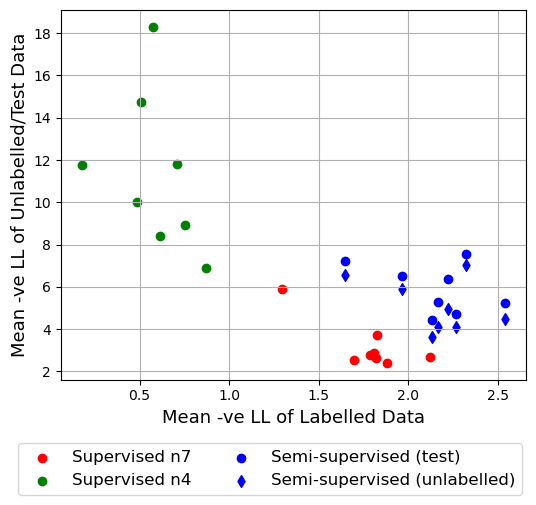

In [13]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_train_full, mean_test_full, color='r', label='Supervised n7')
ax.scatter(mean_train_part, mean_test_part, color='g', label='Supervised n4')
ax.scatter(mean_train_semi, mean_test_semi, color='b', label='Semi-supervised (test)')
ax.scatter(mean_train_semi, mean_train_ul_semi, color='b', marker='d', label='Semi-supervised (unlabelled)')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.45,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve LL of Labelled Data',fontsize=13)
ax.set_ylabel('Mean -ve LL of Unlabelled/Test Data',fontsize=13)

Text(0, 0.5, 'Sample Class Error Rate (%)')

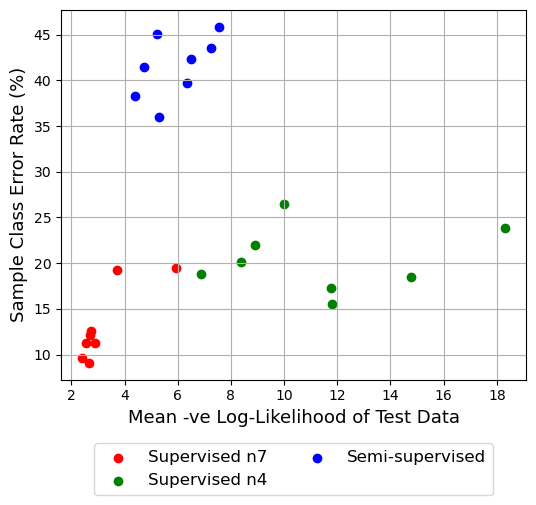

In [14]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_test_full, 100.-acc_total['fullysup'], color='r', label='Supervised n7')
ax.scatter(mean_test_part, 100.-acc_total['partsup'], color='g', label='Supervised n4')
ax.scatter(mean_test_semi, 100.-acc_total['semisup'], color='b', label='Semi-supervised')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve Log-Likelihood of Test Data',fontsize=13)
ax.set_ylabel('Sample Class Error Rate (%)',fontsize=13)

### Schwefel ll acc

In [15]:
ll_all = train_test_ll('Schwefel')

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

In [16]:
distname = 'Schwefel'
scenario_all = ['semisup', 'fullysup', 'partsup']
acc_total = {}
for scenario in scenario_all:
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels/',fname_load))
    acc_runs = np.array([calc_acc_run(d) for d in data_load])*100.
    acc_total[scenario] = np.mean(acc_runs,axis=-1)
acc_total

{'semisup': array([87.7       , 86.73333333, 85.83333333, 89.1       , 86.66666667,
        88.93333333, 90.66666667, 85.86666667]),
 'fullysup': array([96.03333333, 96.33333333, 95.        , 94.5       , 95.9       ,
        94.4       , 95.03333333, 95.2       ]),
 'partsup': array([90.2       , 92.86666667, 90.93333333, 87.86666667, 86.2       ,
        92.8       , 91.23333333, 86.3       ])}

In [17]:
mean_train_semi = [-np.mean(ll) for ll in ll_all['semisup']['train']]
mean_train_ul_semi = [-np.mean(ll) for ll in ll_all['semisup']['train_ul']]
mean_test_semi = [-np.mean(ll) for ll in ll_all['semisup']['test']]

mean_train_full = [-np.mean(ll) for ll in ll_all['fullysup']['train']]
mean_test_full = [-np.mean(ll) for ll in ll_all['fullysup']['test']]

mean_train_part = [-np.mean(ll) for ll in ll_all['partsup']['train']]
mean_test_part = [-np.mean(ll) for ll in ll_all['partsup']['test']]

Text(0, 0.5, 'Mean -ve LL of Unlabelled/Test Data')

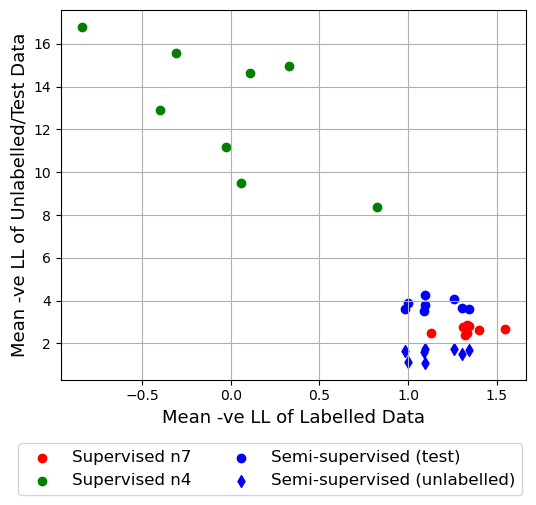

In [18]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_train_full, mean_test_full, color='r', label='Supervised n7')
ax.scatter(mean_train_part, mean_test_part, color='g', label='Supervised n4')
ax.scatter(mean_train_semi, mean_test_semi, color='b', label='Semi-supervised (test)')
ax.scatter(mean_train_semi, mean_train_ul_semi, color='b', marker='d', label='Semi-supervised (unlabelled)')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.45,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve LL of Labelled Data',fontsize=13)
ax.set_ylabel('Mean -ve LL of Unlabelled/Test Data',fontsize=13)

Text(0, 0.5, 'Sample Class Error Rate (%)')

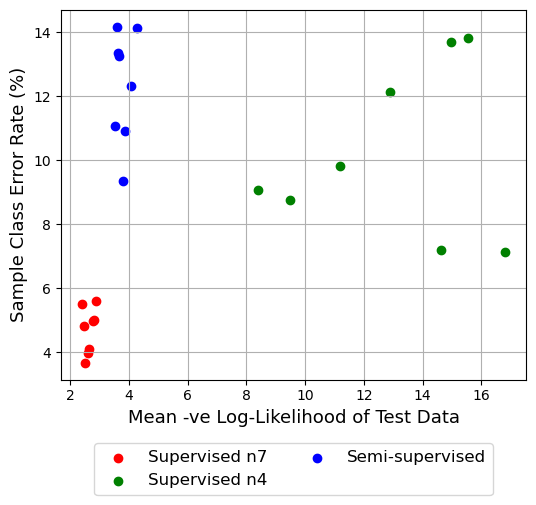

In [19]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_test_full, 100.-acc_total['fullysup'], color='r', label='Supervised n7')
ax.scatter(mean_test_part, 100.-acc_total['partsup'], color='g', label='Supervised n4')
ax.scatter(mean_test_semi, 100.-acc_total['semisup'], color='b', label='Semi-supervised')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve Log-Likelihood of Test Data',fontsize=13)
ax.set_ylabel('Sample Class Error Rate (%)',fontsize=13)

### Whitley ll acc

In [20]:
ll_all = train_test_ll('Whitley')

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

In [21]:
distname = 'Whitley'
scenario_all = ['semisup', 'fullysup', 'partsup']
acc_total = {}
for scenario in scenario_all:
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels/',fname_load))
    acc_runs = np.array([calc_acc_run(d) for d in data_load])*100.
    acc_total[scenario] = np.mean(acc_runs,axis=-1)
acc_total

{'semisup': array([67.26666667, 77.8       , 69.5       , 77.96666667, 65.66666667,
        69.4       , 77.63333333, 68.6       ]),
 'fullysup': array([91.03333333, 91.43333333, 88.3       , 90.66666667, 90.16666667,
        91.66666667, 87.4       , 90.73333333]),
 'partsup': array([83.7       , 86.33333333, 83.83333333, 84.96666667, 83.8       ,
        85.33333333, 84.9       , 83.26666667])}

In [22]:
mean_train_semi = [-np.mean(ll) for ll in ll_all['semisup']['train']]
mean_train_ul_semi = [-np.mean(ll) for ll in ll_all['semisup']['train_ul']]
mean_test_semi = [-np.mean(ll) for ll in ll_all['semisup']['test']]

mean_train_full = [-np.mean(ll) for ll in ll_all['fullysup']['train']]
mean_test_full = [-np.mean(ll) for ll in ll_all['fullysup']['test']]

mean_train_part = [-np.mean(ll) for ll in ll_all['partsup']['train']]
mean_test_part = [-np.mean(ll) for ll in ll_all['partsup']['test']]

Text(0, 0.5, 'Mean -ve LL of Unlabelled/Test Data')

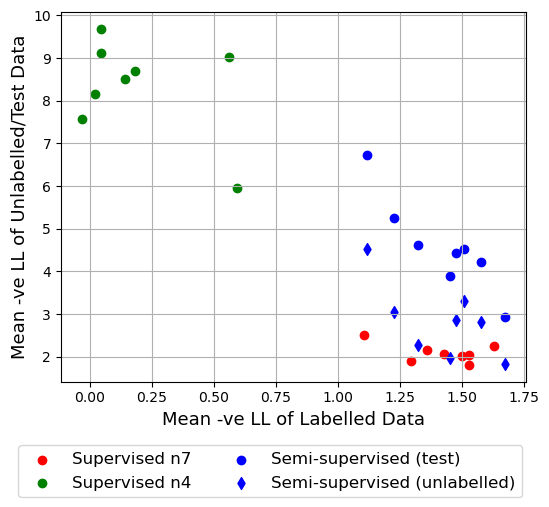

In [23]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_train_full, mean_test_full, color='r', label='Supervised n7')
ax.scatter(mean_train_part, mean_test_part, color='g', label='Supervised n4')
ax.scatter(mean_train_semi, mean_test_semi, color='b', label='Semi-supervised (test)')
ax.scatter(mean_train_semi, mean_train_ul_semi, color='b', marker='d', label='Semi-supervised (unlabelled)')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.45,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve LL of Labelled Data',fontsize=13)
ax.set_ylabel('Mean -ve LL of Unlabelled/Test Data',fontsize=13)

Text(0, 0.5, 'Sample Class Error Rate (%)')

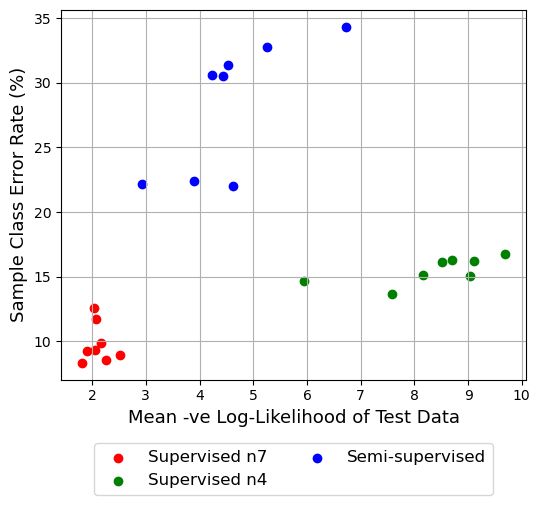

In [24]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_test_full, 100.-acc_total['fullysup'], color='r', label='Supervised n7')
ax.scatter(mean_test_part, 100.-acc_total['partsup'], color='g', label='Supervised n4')
ax.scatter(mean_test_semi, 100.-acc_total['semisup'], color='b', label='Semi-supervised')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve Log-Likelihood of Test Data',fontsize=13)
ax.set_ylabel('Sample Class Error Rate (%)',fontsize=13)

### CR5BP ll acc

In [25]:
ll_all = train_test_ll('CR5BP')

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

In [26]:
distname = 'CR5BP'
scenario_all = ['semisup', 'fullysup', 'partsup']
acc_total = {}
for scenario in scenario_all:
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels/',fname_load))
    acc_runs = np.array([calc_acc_run(d) for d in data_load])*100.
    acc_total[scenario] = np.mean(acc_runs,axis=-1)
acc_total

{'semisup': array([76.1 , 75.45, 90.65, 72.2 , 70.65, 71.4 , 73.25, 60.6 ]),
 'fullysup': array([94.3 , 96.55, 87.25, 90.65, 91.8 , 93.95, 82.6 , 91.65]),
 'partsup': array([89.4 , 86.9 , 90.05, 87.95, 88.6 , 92.5 , 89.35, 93.25])}

In [27]:
mean_train_semi = [-np.mean(ll) for ll in ll_all['semisup']['train']]
mean_train_ul_semi = [-np.mean(ll) for ll in ll_all['semisup']['train_ul']]
mean_test_semi = [-np.mean(ll) for ll in ll_all['semisup']['test']]

mean_train_full = [-np.mean(ll) for ll in ll_all['fullysup']['train']]
mean_test_full = [-np.mean(ll) for ll in ll_all['fullysup']['test']]

mean_train_part = [-np.mean(ll) for ll in ll_all['partsup']['train']]
mean_test_part = [-np.mean(ll) for ll in ll_all['partsup']['test']]

Text(0, 0.5, 'Mean -ve LL of Unlabelled/Test Data')

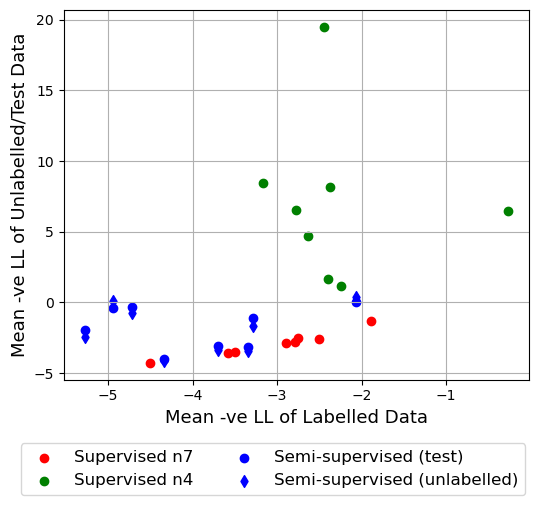

In [28]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_train_full, mean_test_full, color='r', label='Supervised n7')
ax.scatter(mean_train_part, mean_test_part, color='g', label='Supervised n4')
ax.scatter(mean_train_semi, mean_test_semi, color='b', label='Semi-supervised (test)')
ax.scatter(mean_train_semi, mean_train_ul_semi, color='b', marker='d', label='Semi-supervised (unlabelled)')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.45,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve LL of Labelled Data',fontsize=13)
ax.set_ylabel('Mean -ve LL of Unlabelled/Test Data',fontsize=13)

Text(0, 0.5, 'Sample Class Error Rate (%)')

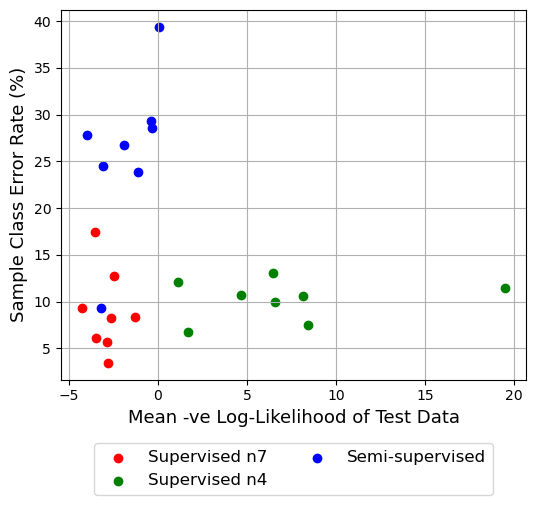

In [29]:
fig, ax = plt.subplots(figsize=(6,8))
ax.scatter(mean_test_full, 100.-acc_total['fullysup'], color='r', label='Supervised n7')
ax.scatter(mean_test_part, 100.-acc_total['partsup'], color='g', label='Supervised n4')
ax.scatter(mean_test_semi, 100.-acc_total['semisup'], color='b', label='Semi-supervised')
ax.grid()

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.4,
                 box.width, box.height * 0.6])

leg = ax.legend(loc='upper center',
                bbox_to_anchor=(0.5,-0.15),
                fontsize=12,
                ncols=2)

ax.set_xlabel('Mean -ve Log-Likelihood of Test Data',fontsize=13)
ax.set_ylabel('Sample Class Error Rate (%)',fontsize=13)

### Rastrigin Conmat

In [10]:
distname = 'Rastrigin'
ind_best_scenario = {
    'fullysup': 7,
    'partsup': 6,
    'semisup': 4,
}
miss_dist_all = {}
mean_dist_all = {}
diff_dist_all = {}
conmat_all = {}
inval_all = {}

conmat_all = {}
for scenario, ind_best in ind_best_scenario.items():
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels',fname_load))
    miss_dist, mean_dist, conmat, inval_p = calc_dist_miss(data_load,ind_best=ind_best_scenario[scenario])
    conmat_all[scenario] = conmat
    miss_dist_all[scenario] = miss_dist
    mean_dist_all[scenario] = mean_dist
    diff_dist_all[scenario] = mean_dist-miss_dist
    conmat_all[scenario] = conmat
    inval_all[scenario] = inval_p

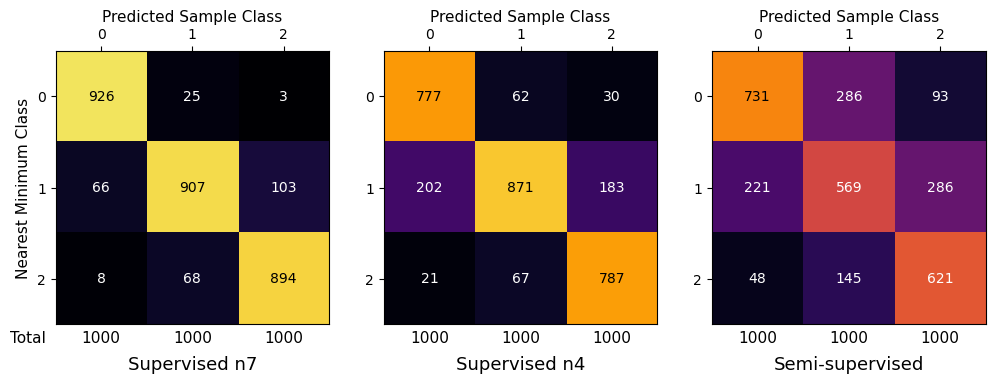

In [11]:
fig, axs = plot_conmats(conmat_all)

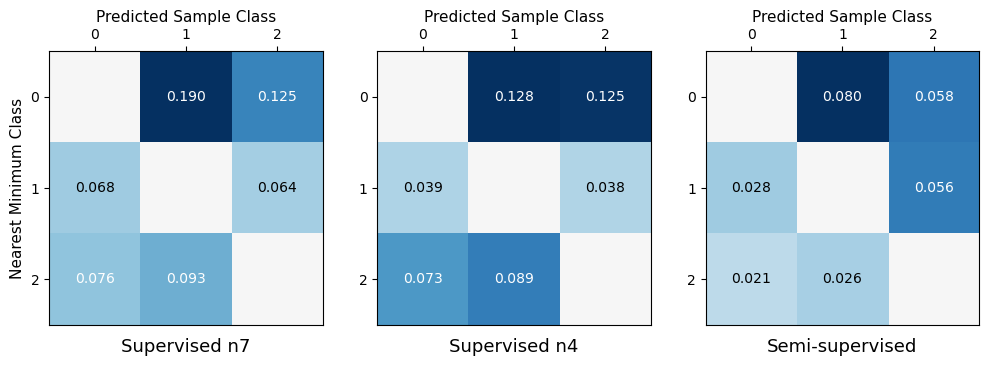

In [12]:
fig, axs = plot_diffmats(diff_dist_all)

### Schwefel Conmat

In [13]:
distname = 'Schwefel'
ind_best_scenario = {
    'fullysup': 1,
    'partsup': 2,
    'semisup': 6
}
miss_dist_all = {}
mean_dist_all = {}
diff_dist_all = {}
conmat_all = {}
inval_all = {}

conmat_all = {}
for scenario, ind_best in ind_best_scenario.items():
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels',fname_load))
    miss_dist, mean_dist, conmat, inval_p = calc_dist_miss(data_load,ind_best=ind_best_scenario[scenario])
    conmat_all[scenario] = conmat
    miss_dist_all[scenario] = miss_dist
    mean_dist_all[scenario] = mean_dist
    diff_dist_all[scenario] = mean_dist-miss_dist
    conmat_all[scenario] = conmat
    inval_all[scenario] = inval_p

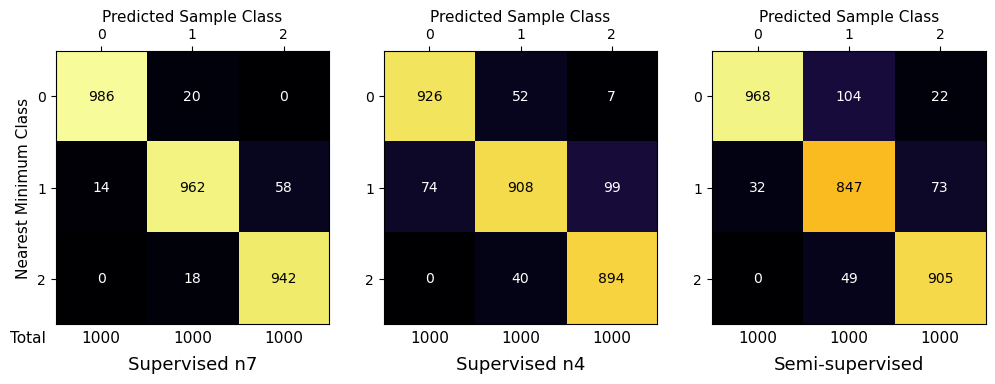

In [14]:
fig, axs = plot_conmats(conmat_all)

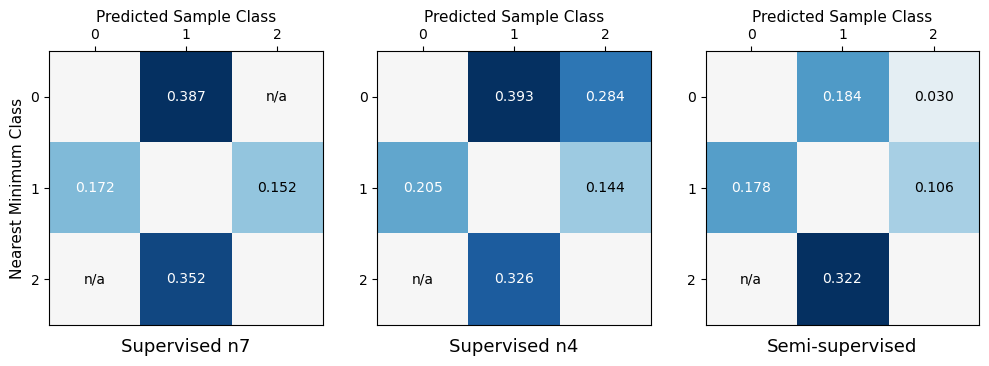

In [15]:
fig, axs = plot_diffmats(diff_dist_all)

### Whitley Conmat

In [16]:
distname = 'Whitley'
ind_best_scenario = {
    'fullysup': 5,
    'partsup': 5,
    'semisup': 1
}
miss_dist_all = {}
mean_dist_all = {}
diff_dist_all = {}
conmat_all = {}
inval_all = {}

conmat_all = {}
for scenario, ind_best in ind_best_scenario.items():
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels',fname_load))
    miss_dist, mean_dist, conmat, inval_p = calc_dist_miss(data_load,ind_best=ind_best_scenario[scenario])
    conmat_all[scenario] = conmat
    miss_dist_all[scenario] = miss_dist
    mean_dist_all[scenario] = mean_dist
    diff_dist_all[scenario] = mean_dist-miss_dist
    conmat_all[scenario] = conmat
    inval_all[scenario] = inval_p

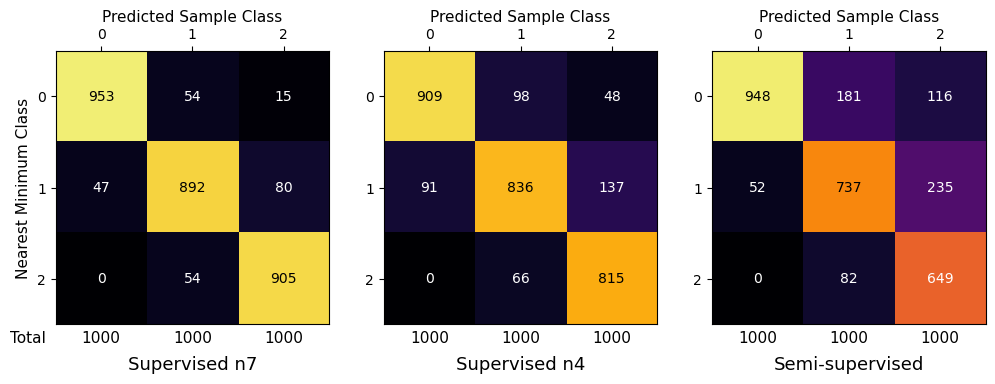

In [17]:
fig, axs = plot_conmats(conmat_all)

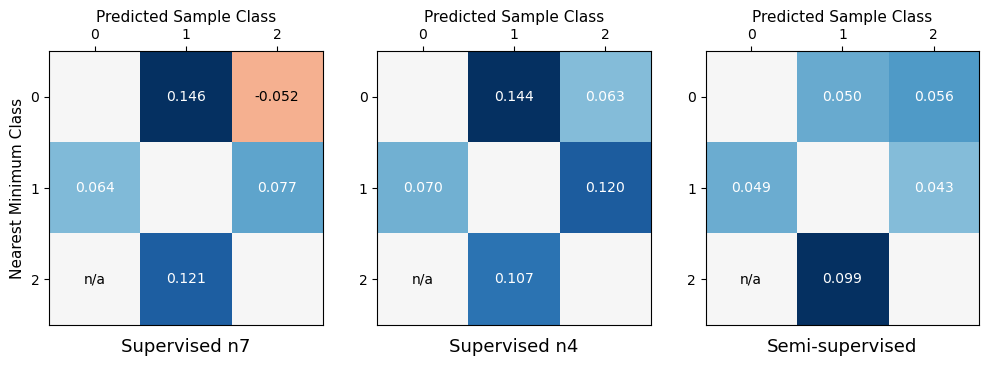

In [18]:
fig, axs = plot_diffmats(diff_dist_all)

### CR5BP Conmat

In [19]:
distname = 'CR5BP'
ind_best_scenario = {
    'fullysup': 1,
    'partsup': 7,
    'semisup': 2
}
miss_dist_all = {}
mean_dist_all = {}
diff_dist_all = {}
conmat_all = {}
inval_all = {}

conmat_all = {}
for scenario, ind_best in ind_best_scenario.items():
    fname_load = f'sampdist_{distname}_{scenario}.npy'
    data_load = np.load(os.path.join(PATH_TO_DATA,'Labels',fname_load))
    miss_dist, mean_dist, conmat, inval_p = calc_dist_miss(data_load,ind_best=ind_best_scenario[scenario])
    conmat_all[scenario] = conmat
    miss_dist_all[scenario] = miss_dist
    mean_dist_all[scenario] = mean_dist
    diff_dist_all[scenario] = mean_dist-miss_dist
    conmat_all[scenario] = conmat
    inval_all[scenario] = inval_p

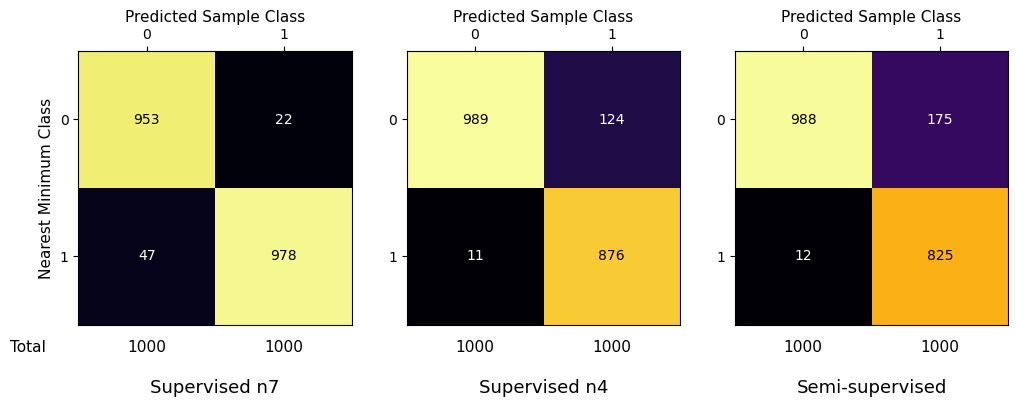

In [20]:
fig, axs = plot_conmats(conmat_all)

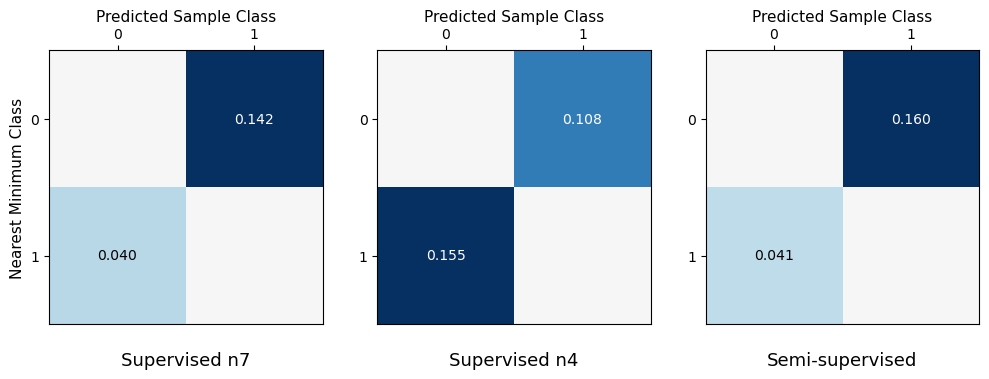

In [21]:
fig, axs = plot_diffmats(diff_dist_all)

## Metastable Training Data

In [5]:
def dpot_dx(s, t,
            w1 = 15.,
            w3 = np.array([2,0.1,2,0.1]),
            c = np.array([[-0.7,0.],
                          [0.,0.7],
                          [0.7,0.],
                          [0,-0.7]]),
            curvature = 0.01):
    """Negative rate of change of potential function"""
    dzdx=-curvature*2*s[:2]
    nc = c.shape[0]
    for k in range(nc):
        dzdx -= w3[k]*w1*np.exp(-w1*((s[0]-c[k,0])**2 + (s[1]-c[k,1])**2))*2*(s[:2]-c[k,:2])
    return np.array([s[2], s[3], dzdx[0], dzdx[1]])

def f_root_1d(s,mu=0.1):
    """Root function for finding equilibrium points"""
    scale = 0.7
    w1=15
    c = np.array([
        [-scale,0.],
        [scale,0.]
    ])
    curvature=0.01;
    w3 = np.array([2.,mu])
    
    dzdx=-curvature*2*s[0]
    nc = c.shape[0]
    for k in range(nc):
        dzdx -= w3[k]*w1*np.exp(-w1*(s[0]-c[k,0])**2)*2*(s[0]-c[k,0])
    return dzdx

### Propagation Plot

In [6]:
mu = 0.05
N_traj = 20

scale = 0.7
w1=15
c = np.array([
    [-scale,0.],
    [scale,0.]
])
curvature=0.01;
xmax_samp = np.sqrt(2./w1)


t_all = 0.01*np.arange(10000)
w3 = np.array([2.,mu])
rng = np.random.default_rng(seed=1234567)
f_prop = partial(dpot_dx,w1=w1,w3=w3,c=c,curvature=curvature)
traj_mu = []
for _ in trange(N_traj):
    s0 = np.zeros(4)
    r_samp = xmax_samp*np.sqrt(rng.random())
    theta_samp = 2.*np.pi*rng.random()
    s0[:2] = c[1,:]+r_samp*np.array([np.cos(theta_samp),np.sin(theta_samp)])
    s_all = odeint(f_prop, s0, t_all)
    traj_mu.append(s_all.copy())

  0%|          | 0/20 [00:00<?, ?it/s]

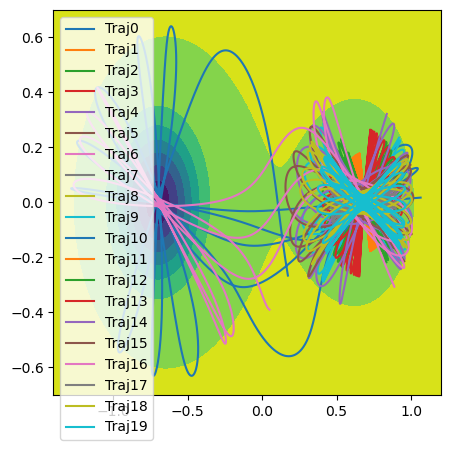

In [7]:
xlims = (-1.4,1.2)
ylims = (-0.7,0.7)
x, y = np.meshgrid(np.linspace(xlims[0],xlims[1],100),np.linspace(ylims[0],ylims[1],100))
z = curvature*(x**2+y**2)

for i in range(2):
    z += -w3[i]*np.exp( -w1 * ((x-c[i,0])**2 + (y-c[i,1])**2) )

fig, ax = plt.subplots(figsize=(5,5))
cs = ax.contourf(x,y,z)
for i,s in enumerate(traj_mu):
    ax.plot(s[:,0],s[:,1],label=f'Traj{i}')
ax.legend()

Text(0.5, 1.0, '$\\Omega(\\mathbf{x})$')

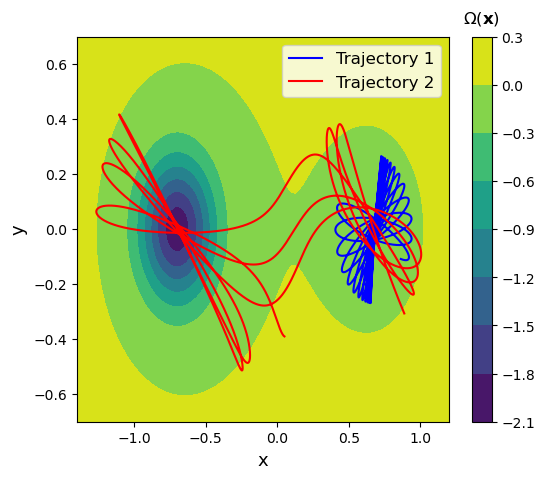

In [8]:
xlims = (-1.4,1.2)
ylims = (-0.7,0.7)
x, y = np.meshgrid(np.linspace(xlims[0],xlims[1],100),np.linspace(ylims[0],ylims[1],100))
z = curvature*(x**2+y**2)

for i in range(2):
    z += -w3[i]*np.exp( -w1 * ((x-c[i,0])**2 + (y-c[i,1])**2) )

fig, ax = plt.subplots(figsize=(6,5))
cs = ax.contourf(x,y,z)
traj_plot = [traj_mu[13],traj_mu[16]]
c_plot = ['b','r']
for i,s in enumerate(traj_plot):
    ax.plot(s[:,0],s[:,1],label=f'Trajectory {i+1}',color=c_plot[i])
ax.set_xlabel('x',fontsize=13)
ax.set_ylabel('y',fontsize=13)
ax.legend(fontsize=12)

divider = make_axes_locatable(ax)
cbar = fig.colorbar(cs)
cbar.ax.set_title(r'$\Omega(\mathbf{x})$',pad=10,fontsize=12)

### Trajectory Data

In [9]:
mu_all = np.linspace(0,0.1,21)
N_traj = 500

scale = 0.7
w1=15
c = np.array([
    [-scale,0.],
    [scale,0.]
])
curvature=0.01;
xmax_samp = np.sqrt(2./w1)

traj_all = []
t_all = 0.01*np.arange(5000)
for mu in tqdm(mu_all):
    w3 = np.array([2.,mu])
    rng = np.random.default_rng(seed=12345678)
    f_prop = partial(dpot_dx,w1=w1,w3=w3,c=c,curvature=curvature)
    traj_mu = []
    for _ in range(N_traj):
        s0 = np.zeros(4)
        r_samp = xmax_samp*np.sqrt(rng.random())
        theta_samp = 2.*np.pi*rng.random()
        s0[:2] = c[1,:]+r_samp*np.array([np.cos(theta_samp),np.sin(theta_samp)])
        s_all = odeint(f_prop, s0, t_all)
        traj_mu.append(s_all.copy())
    traj_all.append(traj_mu.copy())

  0%|          | 0/21 [00:00<?, ?it/s]

In [10]:
d_max = [np.max( np.linalg.norm(np.array(traj)[...,:2]-c[1,:].reshape(1,1,-1),axis=-1), axis=-1 ) for traj in traj_all]
data_save = {
    'mu': [float(mu) for mu in mu_all],
    'd_max': [[float(d) for d in d_mu] for d_mu in d_max]
}
fname_save = 'traj_dipole_max_data_mu_0_0p1_N500_Nt5000.json'
with open(os.path.join(PATH_TO_DATA,'Metastable/',fname_save),'w') as f:
    json.dump(data_save,f)

### Training Data

In [6]:
fname_load = 'traj_dipole_max_data_mu_0_0p1_N500_Nt5000.json'
with open(os.path.join(PATH_TO_DATA,'Metastable/',fname_load),'r') as f:
    data_load = json.load(f)

In [7]:
rmax = 0.5
n_all = np.array([np.sum(np.array(d_max)>rmax) for d_max in data_load['d_max']])

Text(0.5, 0, '$\\mu$')

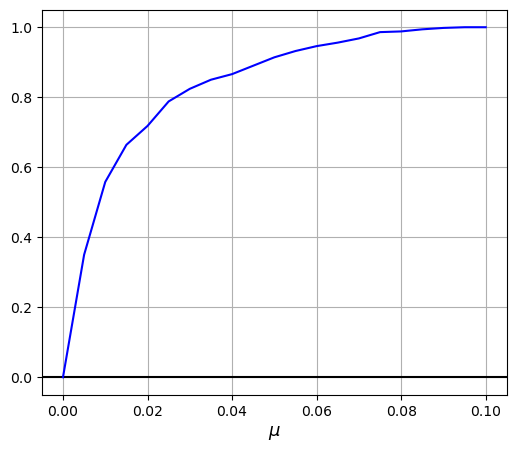

In [8]:
fig, ax = plt.subplots(figsize=(6,5))
ax.axhline(0.,color='k')
ax.plot(data_load['mu'],1.-n_all/500.,color='b')
ax.grid()
ax.set_xlabel(r'$\mu$',fontsize=13)

In [9]:
ind_train_lab = [1,3,6,10,14,17,19]
min_lab = []
c_lab = []
for ind in ind_train_lab:
    mu_norm = -1+0.1*ind
    mu = 0.1*0.5*(mu_norm+1.)
    f_root = partial(f_root_1d,mu=mu)
    x_mu = []
    for x0 in [0.,-0.7,0.7]:
        res = root(f_root,x0,tol=1e-10)
        x_mu.append(np.array([res.x[0], 0.]))
    min_lab.extend([np.append(x,mu_norm) for x in x_mu])
    n = n_all[ind]/500.
    c_lab.extend(
        [[1,0],[0,1],[n,1-n]]
    )
min_lab = np.array(min_lab)
c_lab = np.array(c_lab)
min_params_class_lab = np.hstack([min_lab,c_lab])
print(min_params_class_lab.shape)

(21, 5)


In [10]:
psamp_data_lab = sample_with_noise(min_params_class_lab, 439, 2**13+1024,
                                   N_check = 2**13,
                                   seed_noise = 12345678,
                                   seed_samp = 123456789)

N min 21 min sampled 21


In [ ]:
columns = ['x','y','mu_norm','c0','c1']

psave_tf = tf.constant(psamp_data_lab,dtype=tf.float32)
fname_save = f'traindata_Metastable_mu_0_0p1'
save_tensor_data(psave_tf,dirname=os.path.join(PATH_TO_DATA,'Metastable'),fname=fname_save)

df_save = pd.DataFrame(data=psamp_data_lab,columns=columns)
fname_csv = fname_save+'.csv'
df_save.to_csv(os.path.join(PATH_TO_DATA,'Metastable',fname_csv),index=False)

## Metastable Results

In [5]:
def f_root_1d(s,mu=0.1):
    """Root function for finding equilibrium points"""
    scale = 0.7
    w1=15
    c = np.array([
        [-scale,0.],
        [scale,0.]
    ])
    curvature=0.01;
    w3 = np.array([2.,mu])
    
    dzdx=-curvature*2*s[0]
    nc = c.shape[0]
    for k in range(nc):
        dzdx -= w3[k]*w1*np.exp(-w1*(s[0]-c[k,0])**2)*2*(s[0]-c[k,0])
    return dzdx

In [6]:
fname_load = 'traj_dipole_max_data_mu_0_0p1_N500_Nt5000.json'
with open(os.path.join(PATH_TO_DATA,'Metastable/',fname_load),'r') as f:
    data_load = json.load(f)
rmax = 0.5
n_all = np.array([np.sum(np.array(d_max)>rmax) for d_max in data_load['d_max']])
data_load['mu'] = np.array(data_load['mu'])

### Model ll

In [7]:
ind_train_lab = [1,3,6,10,14,17,19]
min_lab = []
c_lab = []
for ind in ind_train_lab:
    mu_norm = -1+0.1*ind
    mu = 0.1*0.5*(mu_norm+1.)
    f_root = partial(f_root_1d,mu=mu)
    x_mu = []
    for x0 in [0.,-0.7,0.7]:
        res = root(f_root,x0,tol=1e-10)
        x_mu.append(np.array([res.x[0], 0.]))
    min_lab.extend([np.append(x,mu_norm) for x in x_mu])
    n = n_all[ind]/500.
    c_lab.extend(
        [[1,0],[0,1],[n,1-n]]
    )
min_train = np.array(min_lab)
c_train = np.array(c_lab)
print(min_train.shape)

(21, 3)


In [8]:
ind_test = [i for i in range(n_all.shape[0]) if i not in ind_train_lab]
min_lab = []
c_lab = []
for ind in ind_test:
    mu_norm = -1+0.1*ind
    mu = 0.1*0.5*(mu_norm+1.)
    f_root = partial(f_root_1d,mu=mu)
    x_mu = []
    for x0 in [0.,-0.7,0.7]:
        res = root(f_root,x0,tol=1e-10)
        if res.success:
            x_mu.append(np.array([res.x[0], 0.]))
    min_lab.extend([np.append(x,mu_norm) for x in x_mu])
    n = n_all[ind]/500.
    if len(x_mu)==3:
        c_lab.extend(
            [[1,0],[0,1],[n,1-n]]
        )
    else:
        c_lab.extend(
            [[0,1]]
        )
min_test = np.array(min_lab)
c_test = np.array(c_lab)
print(min_test.shape)

(40, 3)


In [9]:
x_train_lab_tf = tf.constant(min_train,dtype=tf.float32)
c_train_lab_tf = tf.constant(c_train,dtype=tf.float32)

x_test_tf = tf.constant(min_test,dtype=tf.float32)
c_test_tf = tf.constant(c_test,dtype=tf.float32)

In [10]:
dirname = os.path.join(PATH_TO_MODELS,'Metastable')
ll_train_lab = []
ll_test = []
for run_no in trange(8):
    fname_load = f'_Metastable_fullysup_run{run_no}'
    model, config = load_model_json(dirname,fname_load,seed=12345678)
    ll_model = model.log_likelihood(x_train_lab_tf, c_train_lab_tf).numpy()
    ll_train_lab.append(ll_model)
    ll_model = model.log_likelihood(x_test_tf, c_test_tf).numpy()
    ll_test.append(ll_model)

  0%|          | 0/8 [00:00<?, ?it/s]

In [11]:
for run, (ll_l,ll_t) in enumerate(zip(ll_train_lab,ll_test)):
    print(f'Run{run} mean ll lab {np.mean(ll_l):<7.3f} test {np.mean(ll_t):<7.3f}')

Run0 mean ll lab 10.172  test 6.648  
Run1 mean ll lab 10.144  test 4.466  
Run2 mean ll lab 9.369   test 3.802  
Run3 mean ll lab 9.505   test 6.581  
Run4 mean ll lab 8.825   test 3.248  
Run5 mean ll lab 9.473   test 6.657  
Run6 mean ll lab 9.817   test 5.656  
Run7 mean ll lab 9.301   test 8.842  


### Model Param Estimate

In [12]:
dirname = os.path.join(PATH_TO_MODELS,'Metastable')
run_no = 7
fname_load = f'_Metastable_fullysup_run{run_no}'
model_best, _ = load_model_json(dirname,fname_load,seed=12345678)

linearly sample mu, find c_ms

In [13]:
N = 101

mu_range = data_load['mu']
x_range = []
for mu in mu_range[1:]:
    f_root = partial(f_root_1d,mu=mu)
    res = root(f_root, 0.7, tol=1e-10)
    if res.success:
        x_range.append(np.array([res.x[0],0.]))
    else:
        x_range.append(np.array([0.497,0.]))
mu_norm = 2.*mu_range[1:]/0.1-1.

cs_range = np.linspace(0,1,N)
c_test = tf.constant([[c_ms,1-c_ms] for c_ms in cs_range],dtype=tf.float32)
cs_max_all = []
for x, mu in zip(x_range,mu_norm):
    x_mu_tf = tf.constant([np.hstack([x,mu])]*N,dtype=tf.float32)
    ll_range = model_best.log_likelihood(x_mu_tf,c_test).numpy()
    cs_max_all.append(cs_range[np.argmax(ll_range)])

Text(0, 0.5, 'Metastability Measure')

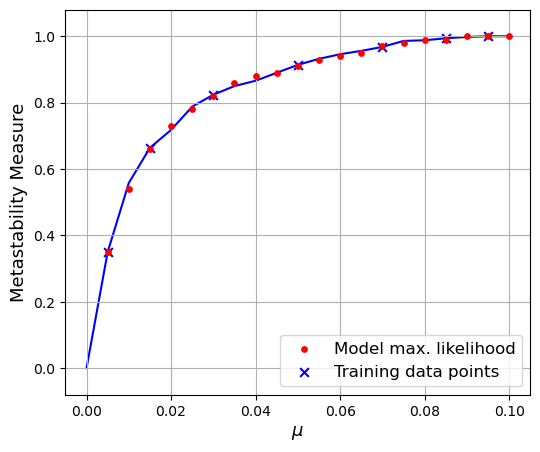

In [14]:
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(data_load['mu'],1.-n_all/500.,color='b',zorder=0)
ax.scatter(mu_range[1:],1.-np.array(cs_max_all),color='r',s=15,zorder=2,label='Model max. likelihood')

ind_train_lab = [1,3,6,10,14,17,19]
n_lab = n_all[ind_train_lab]/500.
mu_lab = data_load['mu'][ind_train_lab]
ax.scatter(mu_lab,1.-n_lab,marker='x',color='b',s=40,zorder=1,label='Training data points')
ax.legend(fontsize=12)
ax.set_ylim(-0.080,1.08)

ax.grid()
ax.set_xlabel(r'$\mu$',fontsize=13)
ax.set_ylabel('Metastability Measure',fontsize=13)

linearly sample c_ms, find mu

In [15]:
N = 100

mu_range = np.linspace(0.0035,0.1,N)
x_range = []
for mu in mu_range:
    f_root = partial(f_root_1d,mu=mu)
    res = root(f_root, 0.7, tol=1e-10)
    if res.success:
        x_range.append(np.array([res.x[0],0.]))
    else:
        x_range.append(np.array([0.497,0.]))
x_range = np.array(x_range)
mu_norm = 2.*mu_range/0.1-1.
x_mu_tf = tf.constant(np.hstack([x_range,mu_norm.reshape(-1,1)]),dtype=tf.float32)

mu_max_all = []
for c_ms in np.linspace(0.,0.8,17):
    c_test = tf.constant([[c_ms,1-c_ms]]*N,dtype=tf.float32)
    ll_range = model_best.log_likelihood(x_mu_tf,c_test).numpy()
    mu_max_all.append(mu_range[np.argmax(ll_range)])

Text(0, 0.5, 'Metastability Measure')

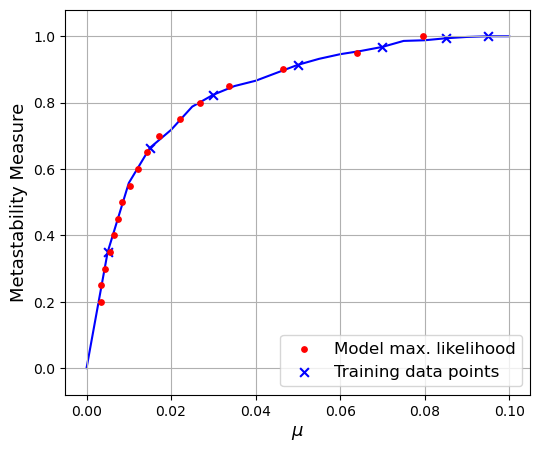

In [16]:
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(data_load['mu'],1.-n_all/500.,color='b',zorder=0)
ax.scatter(mu_max_all,1.-np.linspace(0.,0.8,17),color='r',s=15,zorder=2,label='Model max. likelihood')

ind_train_lab = [1,3,6,10,14,17,19]
n_lab = n_all[ind_train_lab]/500.
mu_lab = data_load['mu'][ind_train_lab]
ax.scatter(mu_lab,1.-n_lab,marker='x',color='b',s=40,zorder=1,label='Training data points')
ax.legend(fontsize=12)
ax.set_ylim(-0.080,1.08)

ax.grid()
ax.set_xlabel(r'$\mu$',fontsize=13)
ax.set_ylabel('Metastability Measure',fontsize=13)

(0.0, 0.103)

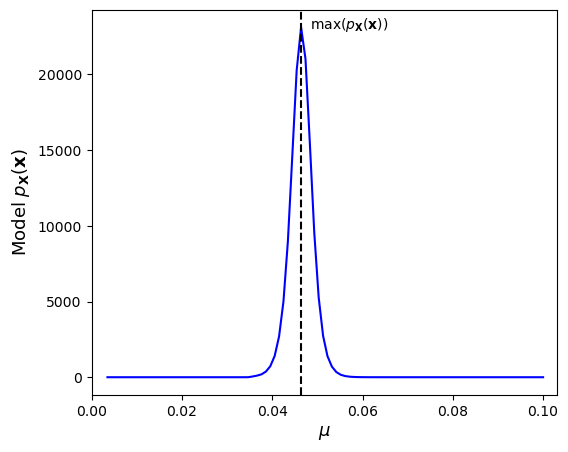

In [17]:
c_ms = 0.9
c_test = tf.constant([[1-c_ms,c_ms]]*N,dtype=tf.float32)
ll_range = model_best.log_likelihood(x_mu_tf,c_test).numpy()
mu_max_all.append(mu_range[np.argmax(ll_range)])

fig, ax = plt.subplots(figsize=(6,5))
ax.plot(mu_range,np.exp(ll_range),color='b')
ax.axvline(mu_range[np.argmax(ll_range)],color='k',linestyle='--')
ax.text(mu_range[np.argmax(ll_range)]+0.002,23e3,r'$\max(p_{\mathbf{X}}(\mathbf{x}))$')
ax.set_xlabel(r'$\mu$',fontsize=13)
ax.set_ylabel(r'Model $p_{\mathbf{X}}(\mathbf{x})$',fontsize=13)
ax.set_xlim(0,0.103)

### Model Sampling

In [18]:
def sample_metastable_model(model, N, c):
    x_samp = np.zeros((0,3))
    ns = N
    while x_samp.shape[0]<N:
        cs = tf.constant([c]*ns,dtype=tf.float32)
        x = model.sample_inv_class(ns, cs).numpy()
        filt_lims = np.abs(x[:,2])<=1
        
        x_keep = x[filt_lims,:]
        x_samp = np.concatenate((x_samp,x_keep), axis=0)
        if x_keep.shape[0]==0:
            ns = ns*10
            print(ns)
        else:
            ns = int((ns-x_keep.shape[0])*ns/x_keep.shape[0])+1
    return x_samp[:N,:]

In [19]:
ind_train_lab = [1,3,6,10,14,17,19]
min_lab = []
c_lab = []
mu_train = []
for ind in ind_train_lab:
    mu_norm = -1+0.1*ind
    mu = 0.1*0.5*(mu_norm+1.)
    f_root = partial(f_root_1d,mu=mu)
    x_mu = []
    for x0 in [0.,-0.7,0.7]:
        res = root(f_root,x0,tol=1e-10)
        x_mu.append(np.array([res.x[0], 0.]))
    min_lab.extend([np.append(x,mu_norm) for x in x_mu])
    mu_train.extend([mu]*3)
    n = n_all[ind]/500.
    c_lab.extend(
        [[1,0],[0,1],[n,1-n]]
    )
min_train = np.array(min_lab)
c_train = np.array(c_lab)
min_train.shape

(21, 3)

In [20]:
dirname = os.path.join(PATH_TO_MODELS,'Metastable')
run_no = 7
fname_load = f'_Metastable_fullysup_run{run_no}'
model_best, _ = load_model_json(dirname,fname_load,seed=12345678)

Text(0, 0.5, 'x')

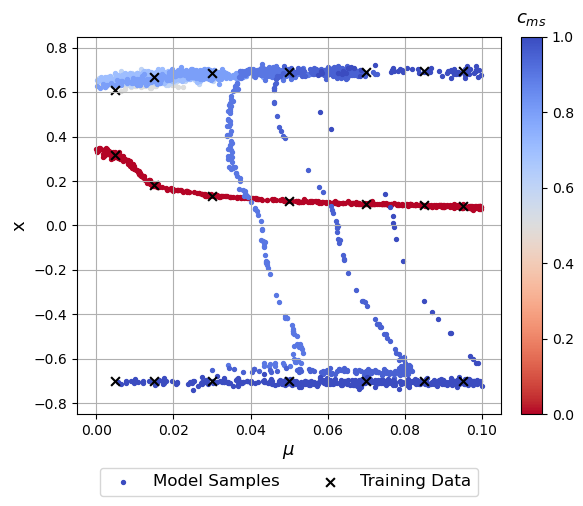

In [21]:
N = 500

fig, ax = plt.subplots(figsize=(6,7))
cms_plot = [0.,0.5,0.6,0.7,0.8,0.9,0.95,1.]
cmap = mpl.colormaps['coolwarm_r']
for c_ms in cms_plot:
    c = [1.-c_ms,c_ms]
    x_samp = sample_metastable_model(model_best, N, c)
    mu_samp = 0.1*0.5*(x_samp[:,2]+1.)
    cs_samp = ax.scatter(mu_samp,x_samp[:,0],s=8,color=cmap(c_ms))
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.2)
cbar = fig.colorbar(cm.ScalarMappable(cmap=cmap), cax=cax)
cbar.ax.set_title(r'$c_{ms}$',pad=10,fontsize=13)
cs_train = ax.scatter(mu_train,min_train[:,0],marker='x',color='k',s=40)

ax.grid()
ax.set_ylim(-0.85,0.85)

box = ax.get_position()
ax.set_position([box.x0, box.y0 + box.height * 0.3,
                 box.width, box.height * 0.7])

leg = ax.legend([cs_samp,cs_train],
                ['Model Samples','Training Data'],
                loc='upper center',
                bbox_to_anchor=(0.5,-0.12),
                fontsize=12,
                ncols=2
               )

ax.set_xlabel(r'$\mu$',fontsize=13)
ax.set_ylabel('x',fontsize=13)